# 配对状态 (D_xy, Δz, θ_a, θ_b) → 转移矩阵 → Infomap 机动聚类（训练 / 测试）

方法参考 O'Shaughnessy et al., *PRX Life* 2, 043006 (2024)：配对构型离散成微状态，按滞后 τ 统计转移矩阵，再用 Infomap 把动力学上连在一起的微状态聚成"机动"（maneuver）。

**与上一版 `20261107_KP_pose_pca_states.ipynb` 的区别**（2026-11-07 讨论后定下）：

1. **状态变量**不再是 PC1–3，而是可解释的四个量：
   - `D_xy`：两条鱼 pec 点的水平距离（mm）
   - `Δz` = z_a − z_b（pec 点，mm，**带符号**，正 = a 在 b 上方）。上一版 PCA 里 PC1 就是 z′ 间距（58% 方差），所以不能像论文那样丢掉 z。
   - `θ_a`、`θ_b`：各自"pec→对方 pec"到"pec→自己 head"的水平夹角，从上往下看逆时针为正；0 = 头朝对方，±π = 背对对方。
2. **两个状态空间**：
   - `FM`：F 永远是 a。FM1、FM2 两组时间序列放进同一个转移矩阵（同一套簇），之后再分开统计 M1 和 M2。FM 和 MF 只是坐标对调，不另算。
   - `MM`：M1→M2 和 M2→M1 两种顺序都放进转移矩阵（对称化；M1/M2 编号本身没有角色含义）。簇会成镜像对出现，Step 3 自动配对（`mirror_partners`）。
3. **划分**：训练 = K_1_1、K_1_2、P_1_1、P_1_2；测试 = K_1_3、P_1_3（同一批鱼的第 3 次录像，不是新个体）。分格边界、τ、簇全部只用训练集确定。
4. **τ**：7 帧（0.042 s）和 17 帧（0.102 s ≈ 论文的 10 帧 @100 fps）两个版本。
5. **不设统一起点**（每个视频从审核账本的分析起点开始，之前的帧本来就是 NaN）。

**步骤**：Step 0 读数据、算四个变量、连续片段 → Step 1 分布与 ACF（仿 Fig. 4、Fig. 2b）→ Step 2 分格（微状态）→ Step 3 转移矩阵 + Infomap（训练集；测试集也独立做一次，供 Step 4 对照）→ Step 4 测试集泛化 + 各实验各配对的使用频率 → Step 5 BORIS 标注验证 → Step 6 总结。

**输出目录**：`<runs_dir>/behavior_features/outputs/20261107_pair_state4d/`（`figures/ thumbs/ data/ figures_index.csv params.json summary.csv`）。命名规则与上一版相同：`<步骤>_<名称>__<单元>__<参数>__<集合>.<扩展名>`。

**本 notebook 不下结论**，只给数值和图；BORIS 只在 Step 5 读取，前面所有选择都不看标注。最终结论只用人工审核过的身份（审核账本之外的帧在读入时已经是 NaN）。

## 参数

所有设置都在下面这个单元。`LABEL_CLASSES` 把 K 组（Courtship / Dash / Chase …）和 P 组（quick circle / follow / attack …）两套不同的 BORIS 词汇合并成共同的类别；顺序 = 重叠时的优先级。没有列出的行为（sneak、other、点事件 Jerk/Ready/Spawn）记为 `unmapped`，不进入评估。

In [1]:
# ============================== Parameters ==============================
from pathlib import Path

RUN_NAME = "20261107_pair_state4d_v1"
OUTPUT_ROOT = None    # None -> <runs_dir>/behavior_features/outputs (paths config)
TRAIN_EXPERIMENTS = ["20251225_K_1_1_FCMC", "20251225_K_1_2_FCMC", "20260112_P_1_1_FCMC", "20260113_P_1_2_FCMC"]
TEST_EXPERIMENTS = ["20251225_K_1_3_FCMC", "20260112_P_1_3_FCMC"]
# Two state spaces. FM: F is always fish a, FM1 and FM2 pooled. MM: both orders pooled (symmetrised).
UNITS = {"FM": [("F", "M1"), ("F", "M2")], "MM": [("M1", "M2"), ("M2", "M1")]}
DPI = 200
THUMB_WIDTH = 900        # also the width of the figures shown inside this notebook

# --- Step 0
MIN_XY_MM = 1.0          # horizontal pec-pec distance or horizontal head-pec length below this -> frame unusable
HEAD_PEC_MAX_MM = None   # optional: drop a fish-frame whose 3D head-pec distance exceeds this (mm); None = off

# --- Step 1
CLOSE_MM = 40.0          # "close" panels of P(theta_a, theta_b)
MAX_LAG_S = 5.0

# --- Step 2: bins (edges from the training set only)
D_MAX_MM = 150.0
N_BINS_D = 10
D_OVERFLOW = True        # one more open bin [D_MAX_MM, inf)
N_BINS_DZ = 8            # even; symmetric about 0; inner edges at quantiles of |dz| (train, all copies)
N_BINS_THETA = 12

# --- Step 3: transitions and Infomap
TAUS = [7, 17]           # frames
KEEP_SELF_LOOPS = True
N_TRIALS = 500
INFOMAP_SEED = 20261107
INFOMAP_WORKERS = 6
COVERAGE = 0.95          # "selected" clusters = largest clusters up to this share of frames
MAX_MATRIX = 40          # at most this many clusters drawn in the cluster x cluster matrix (rest pooled)
N_SHUFFLE = 100
TOP_SHOW = 12            # clusters drawn in cluster maps / usage / ethogram

# --- Step 5: BORIS validation. Order = priority where bouts of one pair overlap (first wins).
LABEL_CLASSES = {
    "wrap": ["wrap"],
    "courtship": ["courtship", "quick circle", "incomplete qc", "touch", "display"],
    "aggression": ["chase", "dash", "attack", "attempted att"],
    "parallel_circling": ["parallel circling", "parallel circle"],
    "approach_follow": ["approach", "follow"],
}
MIN_PURITY = 0.5
ETHOGRAM_EXPERIMENT = "20251225_K_1_1_FCMC"
ETHOGRAM_WINDOW_S = 30.0
ETHOGRAM_START_S = None  # None -> the window with most ETHOGRAM_CLASS frames over FM1 + FM2
ETHOGRAM_CLASS = "courtship"

PARAMETERS = {k: (str(v) if isinstance(v, Path) else v) for k, v in dict(globals()).items()
              if k.isupper() and k != "PARAMETERS"}
print(f"{len(PARAMETERS)} parameters; run {RUN_NAME}")

31 parameters; run 20261107_pair_state4d


## Setup（公共函数，不是分析步骤）

找仓库根目录、读路径配置、建输出目录、定义保存图和读写中间结果的函数。`params.json` 在这里写入参数、日期、库版本。重跑任何一步之前先运行这个单元。新增的计算逻辑在 `scripts/analysis/pair_state4d.py`（有单元测试 `tests/test_pair_state4d.py`）。

In [2]:
import os
import sys
import json
import time
import platform
import importlib

REPO = Path.cwd().resolve()
while not (REPO / "pyproject.toml").exists():
    if REPO.parent == REPO:
        raise RuntimeError("repository root (pyproject.toml) not found above the working directory")
    REPO = REPO.parent
os.chdir(REPO)
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, ListedColormap, BoundaryNorm
import numpy as np
import pandas as pd
from scipy import sparse
from IPython.display import Image as IPImage, display

from scripts.analysis import microstate as M
from scripts.analysis import pose_states as S
from scripts.analysis import pair_state4d as P4
from scripts.analysis.behavior_dataset import resolve_roots

importlib.reload(P4)

_CONFIG, REVIEW_ROOT, _BF_ROOT = resolve_roots(None)
OUT_ROOT = Path(OUTPUT_ROOT) if OUTPUT_ROOT else Path(_BF_ROOT) / "outputs"
L = S.RunLayout(OUT_ROOT / RUN_NAME, dpi=DPI, thumb_width=THUMB_WIDTH)
ALL_EXPERIMENTS = list(TRAIN_EXPERIMENTS) + list(TEST_EXPERIMENTS)
SETS = {"train": list(TRAIN_EXPERIMENTS), "test": list(TEST_EXPERIMENTS)}
if set(TRAIN_EXPERIMENTS) & set(TEST_EXPERIMENTS):
    raise ValueError("an experiment is in both TRAIN and TEST")


def _allow_listed(experiment, final):
    # split.csv is not used here; only the experiments named in the parameter cell may be read.
    if experiment not in ALL_EXPERIMENTS:
        raise PermissionError(f"{experiment} is not in TRAIN_EXPERIMENTS / TEST_EXPERIMENTS")


M.require_access = _allow_listed


def save_fig(fig, step, name, unit, params, set_name, show=False, dpi=None):
    # The only way figures are written: png + thumbnail + row in figures_index.csv.
    p = L.save_fig(fig, step, name, unit, params, set_name, dpi=dpi)
    if show:
        display(IPImage(filename=str(L.thumbs / p.name)))
    return p


def copy_name(a, b):
    return f"{a}{b}"   # FM1, FM2, M1M2, M2M1


COPIES = {u: [copy_name(a, b) for a, b in pairs] for u, pairs in UNITS.items()}
COPY_PAIR = {copy_name(a, b): (a, b) for pairs in UNITS.values() for a, b in pairs}
PAIR_COPIES = ["FM1", "FM2", "M1M2"]           # the three physical pairs, one order each
UNIT_OF = {cp: u for u, cps in COPIES.items() for cp in cps}
PAIR_COLOR = {"FM1": "#1f5fa8", "FM2": "#2e8b3e", "M1M2": "#8e44ad", "M2M1": "#c0392b"}
CLASS_COLOR = {"wrap": "#d62728", "courtship": "#ff7f0e", "aggression": "#7f3c8d",
               "parallel_circling": "#17becf", "approach_follow": "#bcbd22"}


def exp_short(e):
    g, t = M.parse_experiment(e)
    return f"{g}_{t}"


def exp_group(e):
    return M.parse_experiment(e)[0]


PRE = {"hpmax": HEAD_PEC_MAX_MM}
STATE_P = {"dmax": D_MAX_MM, "bd": N_BINS_D, "of": bool(D_OVERFLOW), "bz": N_BINS_DZ, "bth": N_BINS_THETA}


def tau_p(tau):
    return {"tau": int(tau), **STATE_P}


def lib_versions():
    import matplotlib as _mpl, scipy as _sp, PIL as _pil
    out = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
           "scipy": _sp.__version__, "matplotlib": _mpl.__version__, "pillow": _pil.__version__}
    for mod in ("igraph", "sklearn"):
        try:
            out[mod] = getattr(importlib.import_module(mod), "__version__", "unknown")
        except ImportError:
            out[mod] = None
    return out


L.update_params("parameters", PARAMETERS)
L.update_params("run", {"run_name": RUN_NAME, "date": time.strftime("%Y-%m-%d %H:%M:%S"),
                        "output_dir": str(L.root), "review_root": str(REVIEW_ROOT),
                        "paths_config": str(_CONFIG), "platform": platform.platform(),
                        "libraries": lib_versions()})


def load_exp(e):
    return L.load_npz("00", "pairvars", "all", PRE, exp_short(e))


def gather(set_name, copies):
    # All frames of the set, block by block (experiment x copy); segment ids made unique per block.
    vals, seg, exp, cop, frame = [], [], [], [], []
    off = 0
    for ei, e in enumerate(SETS[set_name]):
        z = load_exp(e)
        for ci, cp in enumerate(copies):
            v = z[f"vars_{cp}"].astype(np.float64)
            s = z[f"seg_{cp}"].astype(np.int64)
            s = np.where(s >= 0, s + off, -1)
            if (s >= 0).any():
                off = int(s.max()) + 1
            vals.append(v)
            seg.append(s)
            exp.append(np.full(len(v), ei, np.int16))
            cop.append(np.full(len(v), ci, np.int8))
            frame.append(z["frames"].astype(np.int64))
    return {"vals": np.concatenate(vals), "seg": np.concatenate(seg), "exp": np.concatenate(exp),
            "copy": np.concatenate(cop), "frame": np.concatenate(frame),
            "exp_names": list(SETS[set_name]), "copy_names": list(copies)}


print("output folder", L.root)
print("copies", COPIES)

output folder \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\outputs\20261107_pair_state4d
copies {'FM': ['FM1', 'FM2'], 'MM': ['M1M2', 'M2M1']}


## Step 0 — 读数据、算四个状态变量、连续片段、缺口统计

**做什么**：对 6 个实验读入审核后的 F/M1/M2 三节点 3D 坐标（mm）；对 4 个有序配对（FM1、FM2、M1M2、M2M1）算 `(D_xy, Δz, θ_a, θ_b)`；某帧任一变量无定义（坐标缺失、审核未接受、pec 水平距离或 head-pec 水平长度 < `MIN_XY_MM`）就记为不可用。连续可用帧构成片段，转移只在片段内部计数。

**输入**：review package（`review_data.npz` + 身份审核账本）。

**输出**：`data/00_pairvars__all__base__<实验>.npz`（每帧四个变量和片段号）、`data/00_gap_table__all__base__all.csv`（每个实验 × 三个配对：可用比例、手动删除 / 跟踪丢失 / 距离过近的比例、片段数、最长片段、缺口 p99）、图 `00_head_pec`（head-pec 3D 距离分布，用来决定要不要设 `HEAD_PEC_MAX_MM`）。

20251225_K_1_1_FCMC: 348600 frames @ 166.0 fps, review-blocked 3.41%, head-pec removed fish-frames 0  (1 s)


20251225_K_1_2_FCMC: 348600 frames @ 166.0 fps, review-blocked 5.97%, head-pec removed fish-frames 0  (1 s)


20260112_P_1_1_FCMC: 348600 frames @ 166.0 fps, review-blocked 5.27%, head-pec removed fish-frames 0  (1 s)


20260113_P_1_2_FCMC: 348600 frames @ 166.0 fps, review-blocked 3.86%, head-pec removed fish-frames 0  (1 s)


20251225_K_1_3_FCMC: 348600 frames @ 166.0 fps, review-blocked 6.98%, head-pec removed fish-frames 0  (1 s)


20260112_P_1_3_FCMC: 348600 frames @ 166.0 fps, review-blocked 6.16%, head-pec removed fish-frames 0  (1 s)
  csv data/00_gap_table__all__base__all.csv  rows 18
         experiment   set pair  frames  usable_percent  manually_removed_percent  tracking_lost_percent  too_close_or_vertical_percent  first_usable_s  n_segments  longest_segment_s  median_segment_s  gap_p99_frames
20251225_K_1_1_FCMC train  FM1  348600           95.62                      3.41                   0.36                           0.61           34.92         777             110.05              0.04          236.27
20251225_K_1_1_FCMC train  FM2  348600           95.80                      3.41                   0.19                           0.60           34.92         641              79.93              0.05          274.59
20251225_K_1_1_FCMC train M1M2  348600           95.99                      3.41                   0.42                           0.19           34.92         596             129.49          

  fig figures/00_head_pec__all__base__all.png


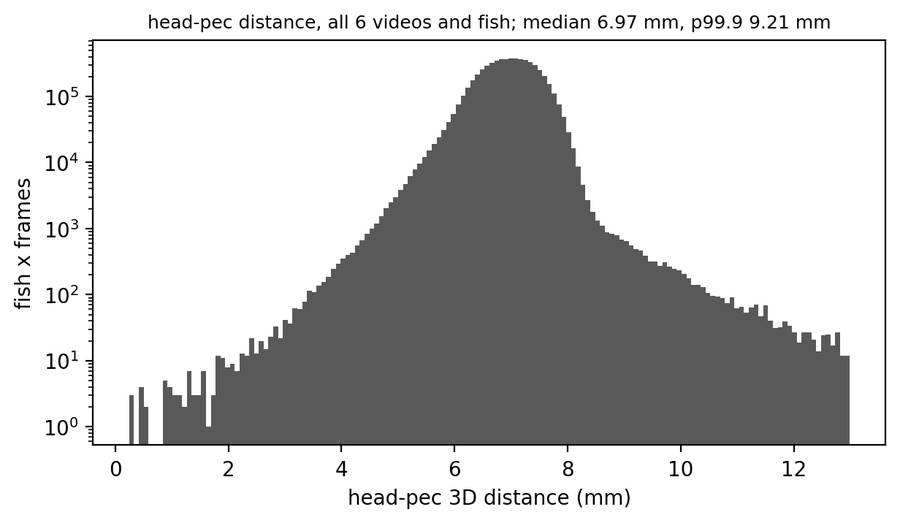

In [3]:
# Step 0: load, pair variables, segments, gap table.
L.clear_log("00")
gap_rows, hp_parts = [], []
for e in ALL_EXPERIMENTS:
    t0 = time.time()
    tr = M.load_trial(e, final=True)
    nodes = np.array(tr["named"], dtype=np.float64, copy=True)
    blocked = np.asarray(tr["blocked"], dtype=bool)
    frames = np.asarray(tr["frames"], dtype=np.int64)
    fps = float(tr["fps"])
    hp = np.linalg.norm(nodes[:, :, P4.HEAD] - nodes[:, :, P4.PEC], axis=-1)   # (T, 3 fish)
    hp_parts.append(hp[np.isfinite(hp)])
    n_hp = 0
    if HEAD_PEC_MAX_MM is not None:
        bad = np.isfinite(hp) & (hp > HEAD_PEC_MAX_MM)
        nodes[bad] = np.nan
        n_hp = int(bad.sum())
    arrays = {"frames": frames, "blocked": blocked, "fps": np.array(fps)}
    for cp, (a, b) in COPY_PAIR.items():
        v = P4.pair_variables(nodes, a, b, MIN_XY_MM)
        ok = np.isfinite(v).all(axis=1)
        arrays[f"vars_{cp}"] = v.astype(np.float32)
        arrays[f"seg_{cp}"] = S.segment_ids(ok).astype(np.int32)
        if cp in PAIR_COPIES:
            ia, ib = P4.FISH.index(a), P4.FISH.index(b)
            fin = np.isfinite(nodes[:, [ia, ib]][:, :, :2]).all(axis=(1, 2, 3))   # head and pec of both
            code = np.zeros(len(v), np.int8)
            code[blocked] = 1
            code[~blocked & ~fin] = 2
            code[~blocked & fin & ~ok] = 3
            g0, g1 = S.bool_runs(~ok)
            s0, s1 = S.bool_runs(ok)
            gaps = g1 - g0
            first = int(np.argmax(ok)) if ok.any() else -1
            gap_rows.append({
                "experiment": e, "set": "train" if e in TRAIN_EXPERIMENTS else "test", "pair": cp,
                "frames": len(v), "usable_percent": 100.0 * ok.mean(),
                "manually_removed_percent": 100.0 * (code == 1).mean(),
                "tracking_lost_percent": 100.0 * (code == 2).mean(),
                "too_close_or_vertical_percent": 100.0 * (code == 3).mean(),
                "first_usable_s": first / fps if first >= 0 else np.nan,
                "n_segments": len(s0), "longest_segment_s": float((s1 - s0).max() / fps) if len(s0) else 0.0,
                "median_segment_s": float(np.median(s1 - s0) / fps) if len(s0) else 0.0,
                "gap_p99_frames": float(np.percentile(gaps, 99)) if len(gaps) else 0.0,
            })
    L.save_npz(arrays, "00", "pairvars", "all", PRE, exp_short(e), verbose=False)
    print(f"{e}: {len(frames)} frames @ {fps:.1f} fps, review-blocked {100 * blocked.mean():.2f}%, "
          f"head-pec removed fish-frames {n_hp}  ({time.time() - t0:.0f} s)")

GAPS = pd.DataFrame(gap_rows)
L.save_csv(GAPS, "00", "gap_table", "all", PRE, "all")
print(GAPS.round(2).to_string(index=False))

hp_all = np.concatenate(hp_parts)
fig, ax = plt.subplots(figsize=(7, 3.6))
hi = float(np.percentile(hp_all, 99.95)) * 1.3
ax.hist(hp_all[hp_all <= hi], bins=150, color="0.35")
ax.set_yscale("log")
ax.set_xlabel("head-pec 3D distance (mm)")
ax.set_ylabel("fish x frames")
if HEAD_PEC_MAX_MM is not None:
    ax.axvline(HEAD_PEC_MAX_MM, color="k", ls="--")
ax.set_title(f"head-pec distance, all 6 videos and fish; median {np.median(hp_all):.2f} mm, "
             f"p99.9 {np.percentile(hp_all, 99.9):.2f} mm", fontsize=9)
save_fig(fig, "00", "head_pec", "all", PRE, "all", show=True)
L.log("00", "done")

## Step 1 — 状态变量的分布与时间尺度

**做什么**（训练集、测试集分别画）：
- `01_dist`：三个配对的 `D_xy`、`Δz` 分布。FM 的 Δz = z_F − z_M（正 = 雌鱼在上）；M1M2 的 Δz = z_M1 − z_M2。
- `01_theta_joint`：P(θ_a, θ_b)，仿论文 Fig. 4b。上排全部距离，下排只用 `D_xy < CLOSE_MM`。横轴 θ_a（FM 是 F；M1M2 是 M1），纵轴 θ_b。
- `01_dxy_dz`：P(D_xy, Δz)，看"上下错开"和"水平错开"怎么组合。
- `01_acf`（训练集）：六个量（D_xy、Δz、cos/sin θ_a、cos/sin θ_b）在片段内的自相关，仿 Fig. 2b；`data/01_acf_times` 是 1/e 时间。

这一步只是描述，不参与后面的选择。

  fig figures/01_dist__all__dmax150-bd10-of-bz8-bth12__train.png


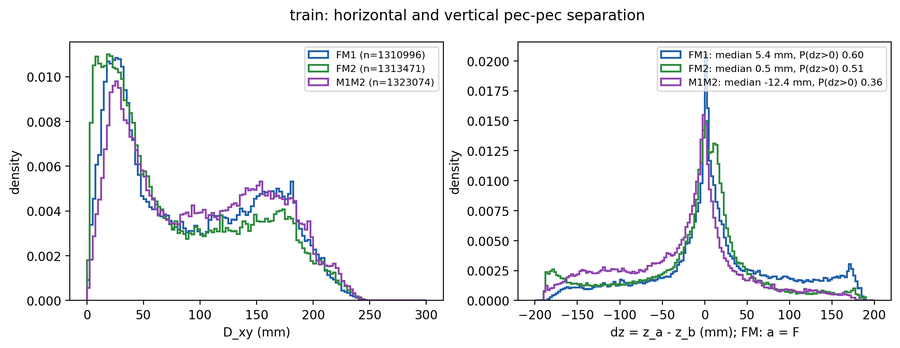

  fig figures/01_theta_joint__all__dmax150-bd10-of-bz8-bth12__train.png


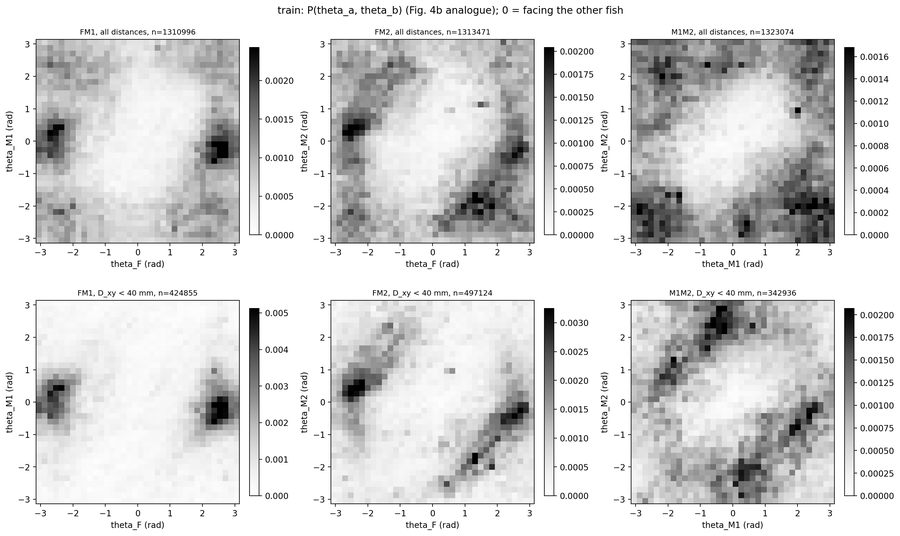

  fig figures/01_dxy_dz__all__dmax150-bd10-of-bz8-bth12__train.png


  fig figures/01_dist__all__dmax150-bd10-of-bz8-bth12__test.png


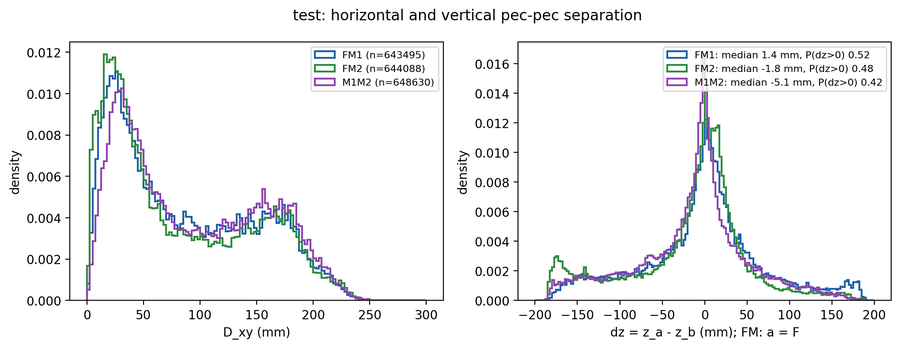

  fig figures/01_theta_joint__all__dmax150-bd10-of-bz8-bth12__test.png


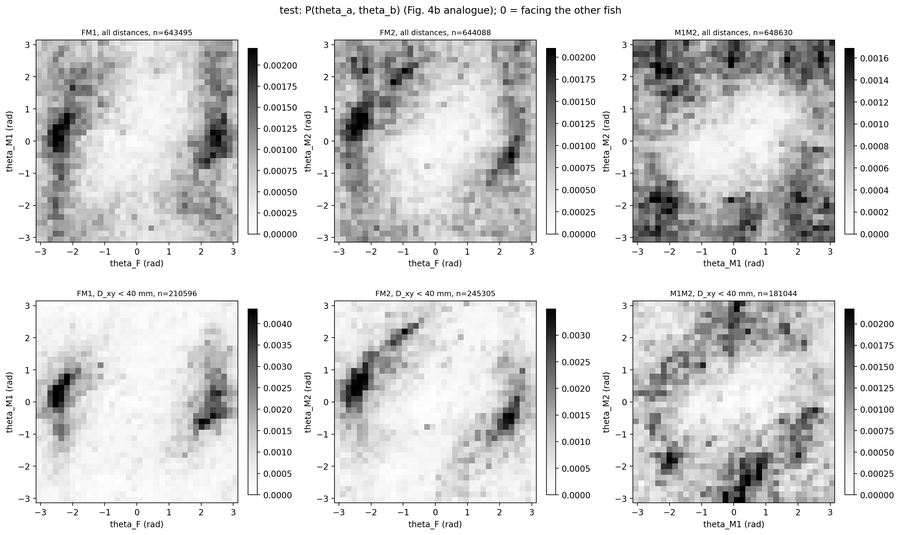

  fig figures/01_dxy_dz__all__dmax150-bd10-of-bz8-bth12__test.png


  fig figures/01_acf__FM__dmax150-bd10-of-bz8-bth12__train.png


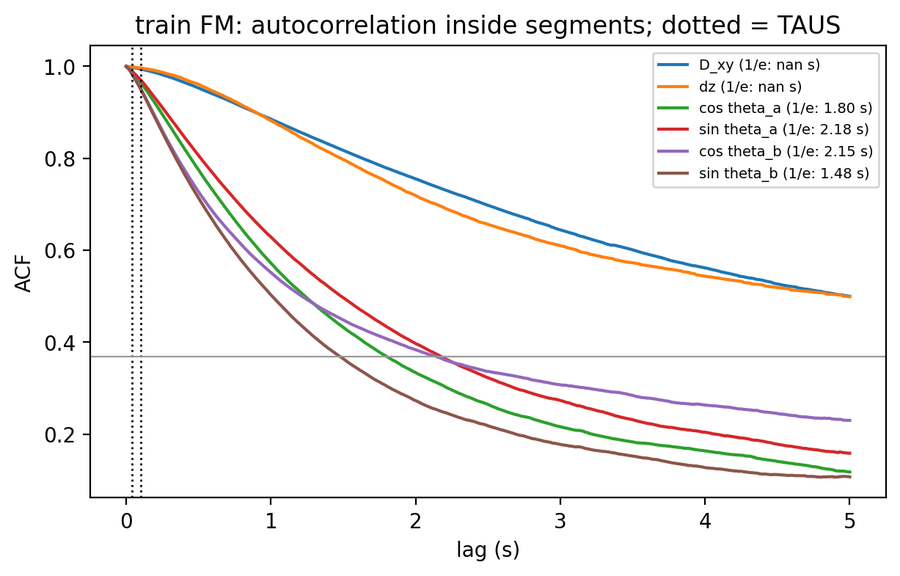

  fig figures/01_acf__MM__dmax150-bd10-of-bz8-bth12__train.png


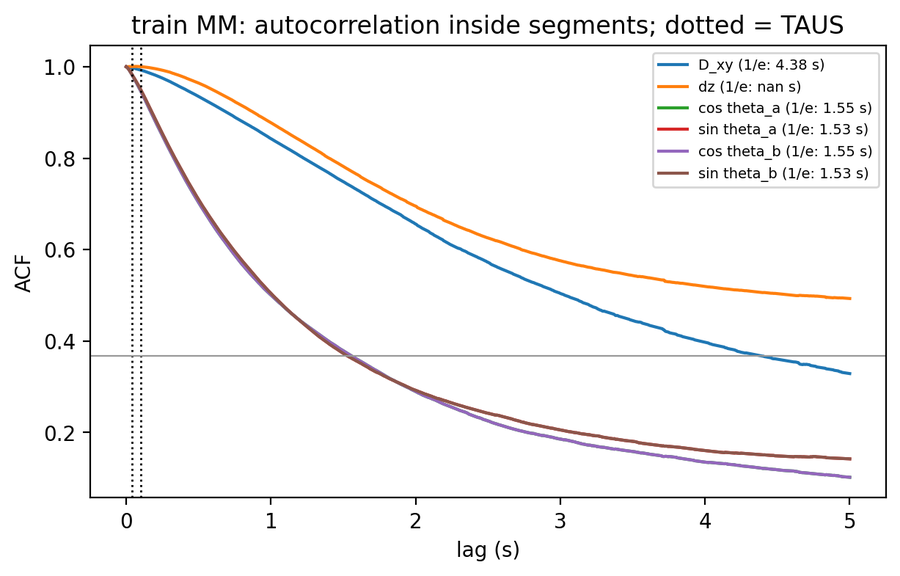

  csv data/01_acf_times__all__dmax150-bd10-of-bz8-bth12__train.csv  rows 12
unit    variable  tau_1e_s
  FM        D_xy       NaN
  FM          dz       NaN
  FM cos theta_a     1.804
  FM sin theta_a     2.181
  FM cos theta_b     2.149
  FM sin theta_b     1.482
  MM        D_xy     4.384
  MM          dz       NaN
  MM cos theta_a     1.555
  MM sin theta_a     1.527
  MM cos theta_b     1.555
  MM sin theta_b     1.527


In [4]:
# Step 1: distributions (Fig. 4 analogue) and autocorrelation times.
L.clear_log("01")
TH_BINS = np.linspace(-np.pi, np.pi, 37)
for set_name in SETS:
    g = gather(set_name, PAIR_COPIES)
    v, cop = g["vals"], g["copy"]
    ok = np.isfinite(v).all(axis=1)
    # D_xy and dz
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    for ci, cp in enumerate(PAIR_COPIES):
        m = ok & (cop == ci)
        axes[0].hist(v[m, 0], bins=np.linspace(0, 300, 121), density=True, histtype="step", lw=1.5,
                     color=PAIR_COLOR[cp], label=f"{cp} (n={m.sum()})")
        axes[1].hist(v[m, 1], bins=np.linspace(-200, 200, 161), density=True, histtype="step", lw=1.5,
                     color=PAIR_COLOR[cp], label=f"{cp}: median {np.median(v[m, 1]):.1f} mm, "
                                                  f"P(dz>0) {np.mean(v[m, 1] > 0):.2f}")
    axes[0].set_xlabel("D_xy (mm)")
    axes[1].set_xlabel("dz = z_a - z_b (mm); FM: a = F")
    for ax in axes:
        ax.set_ylabel("density")
        ax.legend(fontsize=8)
    fig.suptitle(f"{set_name}: horizontal and vertical pec-pec separation")
    save_fig(fig, "01", "dist", "all", STATE_P, set_name, show=True)
    # P(theta_a, theta_b)
    fig, axes = plt.subplots(2, 3, figsize=(15, 9), layout="constrained")
    for row, close in enumerate((False, True)):
        for ci, cp in enumerate(PAIR_COPIES):
            m = ok & (cop == ci)
            if close:
                m &= v[:, 0] < CLOSE_MM
            H, _, _ = np.histogram2d(v[m, 2], v[m, 3], bins=[TH_BINS, TH_BINS])
            H = H / max(H.sum(), 1)
            ax = axes[row, ci]
            im = ax.imshow(H.T, origin="lower", extent=[-np.pi, np.pi, -np.pi, np.pi], cmap="Greys",
                           vmin=0, vmax=np.percentile(H[H > 0], 99.5) if (H > 0).any() else 1)
            a, b = COPY_PAIR[cp]
            ax.set_xlabel(f"theta_{a} (rad)")
            ax.set_ylabel(f"theta_{b} (rad)")
            ax.set_title(f"{cp}, {'D_xy < %g mm' % CLOSE_MM if close else 'all distances'}, n={m.sum()}", fontsize=9)
            fig.colorbar(im, ax=ax, fraction=0.046)
    fig.suptitle(f"{set_name}: P(theta_a, theta_b) (Fig. 4b analogue); 0 = facing the other fish")
    save_fig(fig, "01", "theta_joint", "all", STATE_P, set_name, show=True)
    # P(D_xy, dz)
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for ci, cp in enumerate(PAIR_COPIES):
        m = ok & (cop == ci)
        H, xe, ye = np.histogram2d(v[m, 0], v[m, 1], bins=[np.linspace(0, 250, 51), np.linspace(-200, 200, 81)])
        im = axes[ci].imshow(H.T, origin="lower", extent=[xe[0], xe[-1], ye[0], ye[-1]], aspect="auto",
                             cmap="viridis", norm=LogNorm(vmin=1, vmax=max(H.max(), 2)))
        axes[ci].set_xlabel("D_xy (mm)")
        axes[ci].set_ylabel("dz (mm)")
        axes[ci].set_title(cp, fontsize=9)
        fig.colorbar(im, ax=axes[ci], fraction=0.046, label="frames")
    fig.suptitle(f"{set_name}: joint distribution of D_xy and dz (log colour)")
    save_fig(fig, "01", "dxy_dz", "all", STATE_P, set_name)

# autocorrelation (training set, per unit)
acf_rows = []
for unit in UNITS:
    g = gather("train", COPIES[unit])
    v, seg = g["vals"], g["seg"]
    use = seg >= 0
    fps = float(load_exp(TRAIN_EXPERIMENTS[0])["fps"])
    names = ["D_xy", "dz", "cos theta_a", "sin theta_a", "cos theta_b", "sin theta_b"]
    X = np.column_stack([v[:, 0], v[:, 1], np.cos(v[:, 2]), np.sin(v[:, 2]), np.cos(v[:, 3]), np.sin(v[:, 3])])
    X[~use] = 0.0
    mu, sd = X[use].mean(axis=0), X[use].std(axis=0)
    Z = np.where(use[:, None], (X - mu) / sd, 0.0)
    lag = int(MAX_LAG_S * fps)
    curve, _w = S.acf_segments(Z, seg, lag)
    lag_s = np.arange(lag + 1) / fps
    fig, ax = plt.subplots(figsize=(7, 4))
    for j, nm in enumerate(names):
        t_e = S.time_to_e(lag_s, curve[:, j])
        acf_rows.append({"unit": unit, "variable": nm, "tau_1e_s": t_e})
        ax.plot(lag_s, curve[:, j], label=f"{nm} (1/e: {t_e:.2f} s)")
    for t in TAUS:
        ax.axvline(t / fps, color="k", ls=":", lw=1)
    ax.axhline(np.exp(-1), color="0.6", lw=0.8)
    ax.set_xlabel("lag (s)")
    ax.set_ylabel("ACF")
    ax.legend(fontsize=7)
    ax.set_title(f"train {unit}: autocorrelation inside segments; dotted = TAUS")
    save_fig(fig, "01", "acf", unit, STATE_P, "train", show=True)
ACF = pd.DataFrame(acf_rows)
L.save_csv(ACF, "01", "acf_times", "all", STATE_P, "train")
print(ACF.round(3).to_string(index=False))
L.log("01", "done")

## Step 2 — 分格（微状态）

**做什么**：
- `D_xy`：0–`D_MAX_MM` 等宽 `N_BINS_D` 格，再加一格 `[D_MAX_MM, ∞)`（不丢远距离帧）。
- `Δz`：`N_BINS_DZ` 格，关于 0 对称；内部边界取训练集全部配对 |Δz| 的分位数（每半边各格帧数大致相等），最外两格开放。用 |Δz| 分格再按符号镜像，保证 M1↔M2 交换时状态严格一一对应。
- `θ_a`、`θ_b`：[−π, π] 等宽 `N_BINS_THETA` 格。
- 联合状态数 = 11 × 8 × 12 × 12 = 12672（默认参数）。

边界只用训练集确定，测试集直接套用。打印每个单元被占用的状态数，以及 MM 的对称性检查（M2M1 副本的状态应该恰好是 M1M2 副本状态的交换映射，比例应为 1）。

**输出**：`data/02_bin_edges__all__…__train.json`、`data/02_microstates__<FM|MM>__…__<train|test>.npz`（每帧状态、片段号、实验、副本、帧号、四个变量）、图 `02_occupancy`。

In [5]:
# Step 2: bin edges from the training set, joint microstates for train and test.
L.clear_log("02")
_tr = np.concatenate([gather("train", COPIES[u])["vals"] for u in UNITS])
DZ_EDGES = P4.symmetric_dz_edges(np.abs(_tr[np.isfinite(_tr[:, 1]), 1]), N_BINS_DZ)
EDGES = P4.make_edges(D_MAX_MM, N_BINS_D, D_OVERFLOW, DZ_EDGES, N_BINS_THETA)
WIDTHS = [len(e) - 1 for e in EDGES]
N_STATES = int(np.prod(WIDTHS))
SWAP = P4.swap_state_map(WIDTHS)
del _tr
L.save_json({"variables": list(P4.VARIABLES), "edges": [e.tolist() for e in EDGES], "widths": WIDTHS,
             "n_states": N_STATES, "units": ["mm", "mm", "rad", "rad"]}, "02", "bin_edges", "all", STATE_P, "train")
print("widths", WIDTHS, "states", N_STATES)
print("dz edges (mm)", np.round(DZ_EDGES, 1))

for set_name in SETS:
    for unit in UNITS:
        g = gather(set_name, COPIES[unit])
        bins, state, _w = P4.encode(g["vals"], EDGES)
        state[g["seg"] < 0] = -1
        L.save_npz({"state": state.astype(np.int32), "seg": g["seg"].astype(np.int64), "exp": g["exp"],
                    "copy": g["copy"], "frame": g["frame"], "vals": g["vals"].astype(np.float32),
                    "exp_names": np.array(g["exp_names"]), "copy_names": np.array(g["copy_names"])},
                   "02", "microstates", unit, STATE_P, set_name, verbose=False)
        occ = np.bincount(state[state >= 0], minlength=N_STATES)
        msg = (f"[{set_name} {unit}] frames {len(state)}  with a state {int((state >= 0).sum())} "
               f"({100 * (state >= 0).mean():.1f}%)  occupied states {int((occ > 0).sum())} / {N_STATES}  "
               f">= 50 visits {int((occ >= 50).sum())}")
        if unit == "MM":
            # the M2M1 copy must be the exact swap of the M1M2 copy, frame by frame
            pairs_ok, pairs_n = 0, 0
            for ei in range(len(g["exp_names"])):
                a = state[(g["exp"] == ei) & (g["copy"] == 0)]
                b = state[(g["exp"] == ei) & (g["copy"] == 1)]
                m = (a >= 0) & (b >= 0)
                pairs_ok += int((SWAP[a[m]] == b[m]).sum())
                pairs_n += int(m.sum())
            msg += f"  swap check {pairs_ok / max(pairs_n, 1):.6f}"
        print(msg)
        if set_name == "train":
            fig, axes = plt.subplots(1, 5, figsize=(20, 3.4))
            ranked = np.sort(occ[occ > 0])[::-1]
            axes[0].loglog(np.arange(1, len(ranked) + 1), ranked, ".", ms=2)
            axes[0].set_xlabel("state rank")
            axes[0].set_ylabel("frames")
            axes[0].set_title(f"occupied {int((occ > 0).sum())}/{N_STATES}", fontsize=9)
            for j, nm in enumerate(P4.VARIABLES):
                b = bins[(state >= 0), j]
                axes[j + 1].bar(np.arange(WIDTHS[j]), np.bincount(b, minlength=WIDTHS[j]), color="#4C78A8")
                axes[j + 1].set_xlabel(f"{nm} bin")
                axes[j + 1].set_title(nm, fontsize=9)
            fig.suptitle(f"train {unit}: microstate occupancy")
            save_fig(fig, "02", "occupancy", unit, STATE_P, "train")
L.log("02", "done")

  json data/02_bin_edges__all__dmax150-bd10-of-bz8-bth12__train.json
widths [11, 8, 12, 12] states 12672
dz edges (mm) [ -inf -92.  -33.1 -10.7   0.   10.7  33.1  92.    inf]


[train FM] frames 2788800  with a state 2624467 (94.1%)  occupied states 12291 / 12672  >= 50 visits 9129


  fig figures/02_occupancy__FM__dmax150-bd10-of-bz8-bth12__train.png


[train MM] frames 2788800  with a state 2646148 (94.9%)  occupied states 12308 / 12672  >= 50 visits 9708  swap check 1.000000


  fig figures/02_occupancy__MM__dmax150-bd10-of-bz8-bth12__train.png


[test FM] frames 1394400  with a state 1287583 (92.3%)  occupied states 11602 / 12672  >= 50 visits 6332


[test MM] frames 1394400  with a state 1297260 (93.0%)  occupied states 11836 / 12672  >= 50 visits 7112  swap check 1.000000


## Step 3 — 转移矩阵与 Infomap 聚类

**做什么**：对每个单元（FM、MM）、每个 τ：(t, t+τ) 两帧都有状态且在同一片段内才计数；所有实验、所有副本合并成一个矩阵；行归一化后作为加权有向图跑 Infomap（python-igraph，`N_TRIALS` 次）。簇按覆盖帧数降序编号（C0 最大）。**训练集**的结果是主结果；**测试集**也独立跑一次，只在 Step 4 用于对照。

**输出**（训练集）：
- `data/03_state_clusters`：状态 → 簇（Step 4、5 用它把测试集投到训练集的簇上）。
- `data/03_cluster_stats`：每簇状态数、帧数、簇内转移占比（含/不含对角线）、平均停留时间、D_xy 和 Δz 的中位数、θ_a 和 θ_b 的圆均值、来自各副本的比例（FM：FM1 vs FM2；MM：M1M2 vs M2M1）、来自 K 组的比例；MM 另有镜像配对（`partner`、`overlap`、`mutual`、`merged`）。
- `data/03_within_summary`：簇数、覆盖 95% 需要的簇数、簇内转移占比和打乱 `N_SHUFFLE` 次的参照。**按簇排序后矩阵总会显得有块，要对照打乱参照看。**
- 图：`03_cluster_matrix`（簇×簇转移，最多 `MAX_MATRIX` 个簇）、`03_state_block`（状态级块对角，稀疏散点画法）、`03_cluster_theta` 和 `03_cluster_dxy_dz`（最大 `TOP_SHOW` 个簇在 θ_a×θ_b 和 D_xy×Δz 上的占用，仿 Fig. S12，用来给簇命名）。

In [6]:
# Step 3: transitions + Infomap (train = main result; test run independently for Step 4).
L.clear_log("03")
INFOMAP = S.resolve_infomap_backend()
BACKEND_TAG = f"{INFOMAP['backend']} {INFOMAP['version']}"
L.update_params("infomap", {**INFOMAP, "N_TRIALS": N_TRIALS, "seed": INFOMAP_SEED,
                            "KEEP_SELF_LOOPS": KEEP_SELF_LOOPS, "workers": INFOMAP_WORKERS})
print("Infomap backend:", BACKEND_TAG)


def load_micro(unit, set_name):
    return L.load_npz("02", "microstates", unit, STATE_P, set_name)


def graph_input(counts):
    c = sparse.csr_matrix(counts, dtype=np.float64)
    keep = np.flatnonzero((np.asarray(c.sum(axis=1)).ravel() > 0) | (np.asarray(c.sum(axis=0)).ravel() > 0))
    sub = c[keep][:, keep].tolil()
    if not KEEP_SELF_LOOPS:
        sub.setdiag(0)
    sub = sub.tocsr()
    sub.eliminate_zeros()
    return keep, S.row_normalize(sub)


def run_jobs(jobs, trials):
    from concurrent.futures import ProcessPoolExecutor
    if INFOMAP_WORKERS <= 1:
        return {k: S.run_infomap(p, trials, INFOMAP_SEED, INFOMAP["backend"]) for k, p in jobs}
    with ProcessPoolExecutor(max_workers=INFOMAP_WORKERS) as ex:
        fut = {k: ex.submit(S.run_infomap, p, trials, INFOMAP_SEED, INFOMAP["backend"]) for k, p in jobs}
        return {k: f.result() for k, f in fut.items()}


def relabel(raw, keep, state_frames):
    # Renumber modules by covered frames (0 = most); states outside the graph get -1.
    lab = np.full(N_STATES, -1, dtype=np.int64)
    lab[keep] = raw
    k = int(raw.max()) + 1
    cover = np.bincount(lab[keep], weights=state_frames[keep], minlength=k)
    order = np.lexsort((np.arange(k), -cover))
    new = np.empty(k, dtype=np.int64)
    new[order] = np.arange(k)
    out = np.full(N_STATES, -1, dtype=np.int64)
    out[keep] = new[raw]
    return out, cover[order]


CTX = {}
jobs = []
for set_name in SETS:
    for unit in UNITS:
        mic = load_micro(unit, set_name)
        st, seg = mic["state"].astype(np.int64), mic["seg"]
        for tau in TAUS:
            counts, n_pairs = S.transition_counts(st, seg, int(tau), N_STATES)
            keep, prob = graph_input(counts)
            CTX[(set_name, unit, tau)] = {"counts": counts, "keep": keep, "n_pairs": n_pairs}
            jobs.append(((set_name, unit, tau), prob))
            print(f"[{set_name} {unit} tau {tau}] pairs {n_pairs}  graph nodes {len(keep)}  edges {prob.nnz}  "
                  f"diagonal share {counts.diagonal().sum() / max(counts.sum(), 1):.3f}")
t0 = time.time()
RESULTS = run_jobs(jobs, N_TRIALS)
print(f"{len(jobs)} Infomap runs x {N_TRIALS} trials: {time.time() - t0:.0f} s")

LABELS = {}   # (set, unit, tau) -> state -> cluster
for (set_name, unit, tau), (raw, codelength) in RESULTS.items():
    st = load_micro(unit, set_name)["state"].astype(np.int64)
    sf = np.bincount(st[st >= 0], minlength=N_STATES).astype(float)
    lab, cover = relabel(raw, CTX[(set_name, unit, tau)]["keep"], sf)
    LABELS[(set_name, unit, tau)] = lab
    CTX[(set_name, unit, tau)].update({"cover": cover, "codelength": codelength, "state_frames": sf})
    tab = pd.DataFrame({"state": np.arange(N_STATES), "cluster": lab, "n_frames": sf.astype(int)})
    dec = P4.decode(np.arange(N_STATES), WIDTHS)
    for j, nm in enumerate(P4.VARIABLES):
        tab[f"bin_{nm}"] = dec[:, j]
    if unit == "MM":
        tab["swap_state"] = SWAP
    L.save_csv(tab, "03", "state_clusters", unit, tau_p(tau), set_name, verbose=False)
print("state -> cluster tables written")

Infomap backend: python-igraph 1.0.0


[train FM tau 7] pairs 2586504  graph nodes 12286  edges 126829  diagonal share 0.653


[train FM tau 17] pairs 2555257  graph nodes 12276  edges 164321  diagonal share 0.446


[train MM tau 7] pairs 2628250  graph nodes 12306  edges 157872  diagonal share 0.616
[train MM tau 17] pairs 2609858  graph nodes 12306  edges 214290  diagonal share 0.400


[test FM tau 7] pairs 1270435  graph nodes 11584  edges 87102  diagonal share 0.630
[test FM tau 17] pairs 1255895  graph nodes 11574  edges 107515  diagonal share 0.411


[test MM tau 7] pairs 1287398  graph nodes 11830  edges 112106  diagonal share 0.578
[test MM tau 17] pairs 1276646  graph nodes 11828  edges 144852  diagonal share 0.350


8 Infomap runs x 500 trials: 686 s


state -> cluster tables written



[train FM tau 7 (0.042 s)] clusters 2282; 1597 cover 95% of frames; largest 0.9%; within 0.807 (shuffle 0.653), no diagonal 0.445 (shuffle 0.001)
 cluster  n_states  frame_fraction  mean_dwell_s  within_fraction_nodiag  D_xy_median  dz_median  theta_a_mean  theta_b_mean  share_FM1  share_K
       0         7           0.009         0.108                   0.449       23.086      3.299        -2.522         0.043      0.707    0.289
       1        11           0.008         0.181                   0.653        7.803     15.435         1.449        -1.460      0.204    0.797
       2         4           0.006         0.106                   0.388       23.009      3.483         2.546        -0.452      0.684    0.256
       3        11           0.006         0.158                   0.602        7.692     17.877        -1.698         1.915      0.111    0.897
       4         7           0.006         0.134                   0.524        8.424     16.347         2.733        -0.405    

  fig figures/03_cluster_matrix__FM__tau7-dmax150-bd10-of-bz8-bth12__train.png


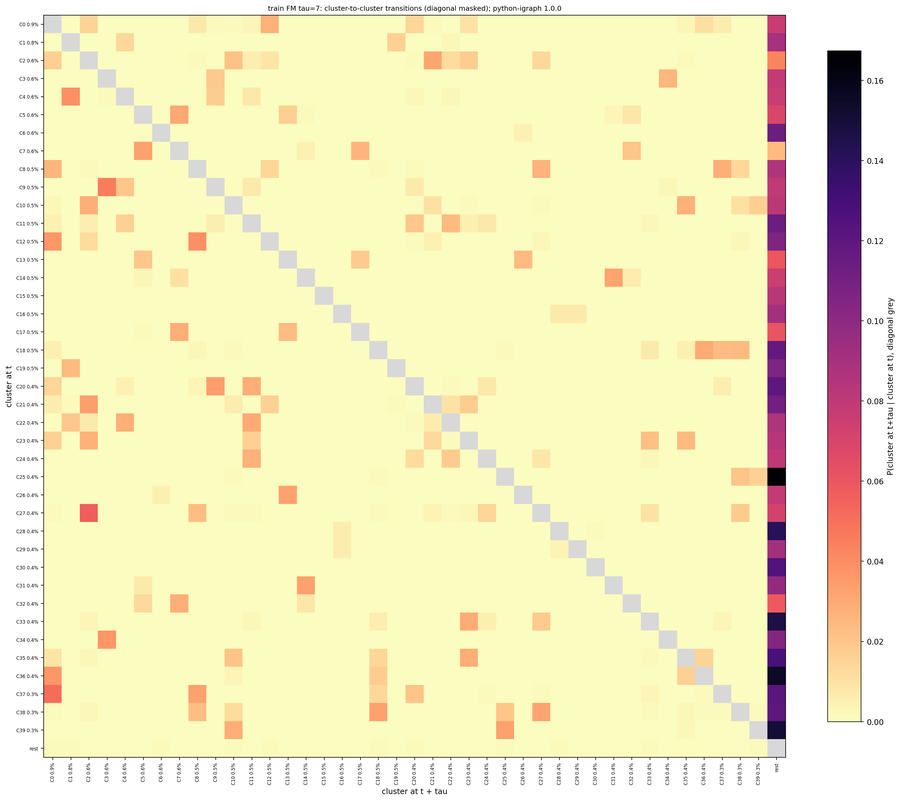

  fig figures/03_state_block__FM__tau7-dmax150-bd10-of-bz8-bth12__train.png


  fig figures/03_cluster_theta__FM__tau7-dmax150-bd10-of-bz8-bth12__train.png


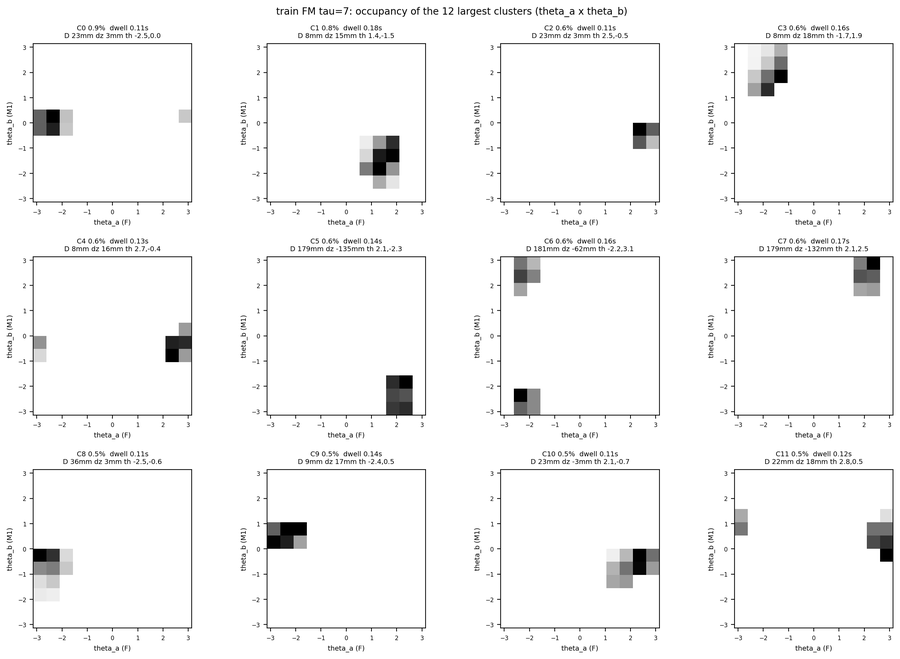

  fig figures/03_cluster_dxy_dz__FM__tau7-dmax150-bd10-of-bz8-bth12__train.png



[train FM tau 17 (0.102 s)] clusters 1225; 807 cover 95% of frames; largest 1.7%; within 0.705 (shuffle 0.446), no diagonal 0.468 (shuffle 0.001)
 cluster  n_states  frame_fraction  mean_dwell_s  within_fraction_nodiag  D_xy_median  dz_median  theta_a_mean  theta_b_mean  share_FM1  share_K
       0        42           0.017         0.137                   0.523       40.044      0.862         2.901        -0.522      0.578    0.330
       1        44           0.013         0.115                   0.454       25.103      4.466        -2.405         0.840      0.479    0.465
       2        40           0.013         0.115                   0.452       45.650     -0.682        -2.825         0.502      0.514    0.437
       3        54           0.012         0.111                   0.556       22.283      3.392        -2.095        -0.816      0.610    0.323
       4        21           0.011         0.144                   0.446       30.123     18.883         2.896        -0.529    

  fig figures/03_cluster_matrix__FM__tau17-dmax150-bd10-of-bz8-bth12__train.png


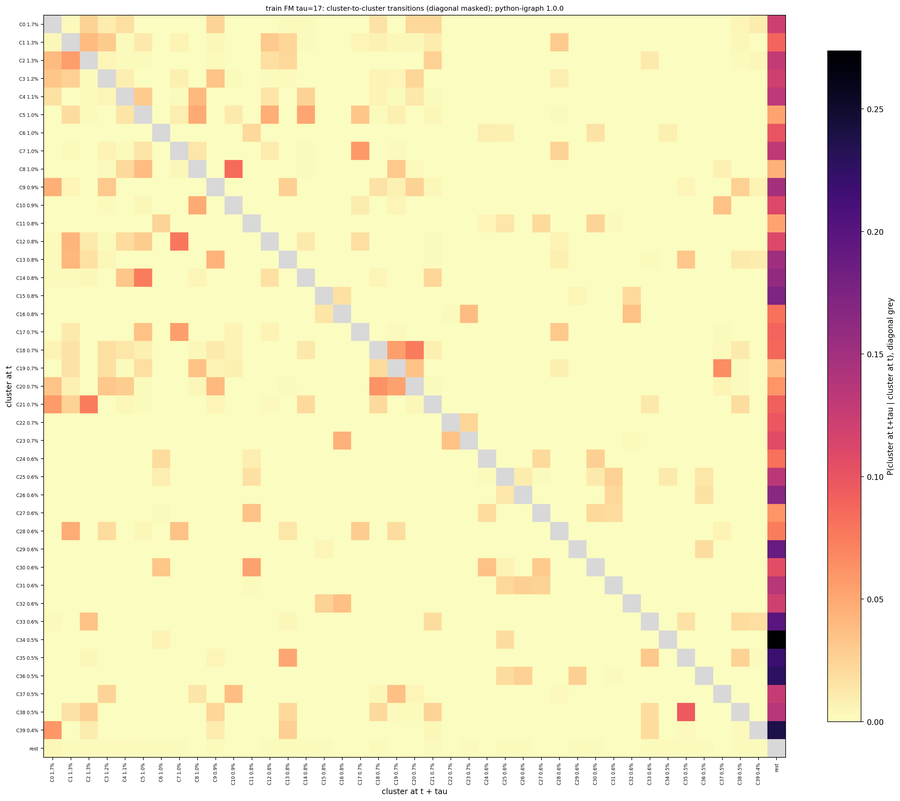

  fig figures/03_state_block__FM__tau17-dmax150-bd10-of-bz8-bth12__train.png


  fig figures/03_cluster_theta__FM__tau17-dmax150-bd10-of-bz8-bth12__train.png


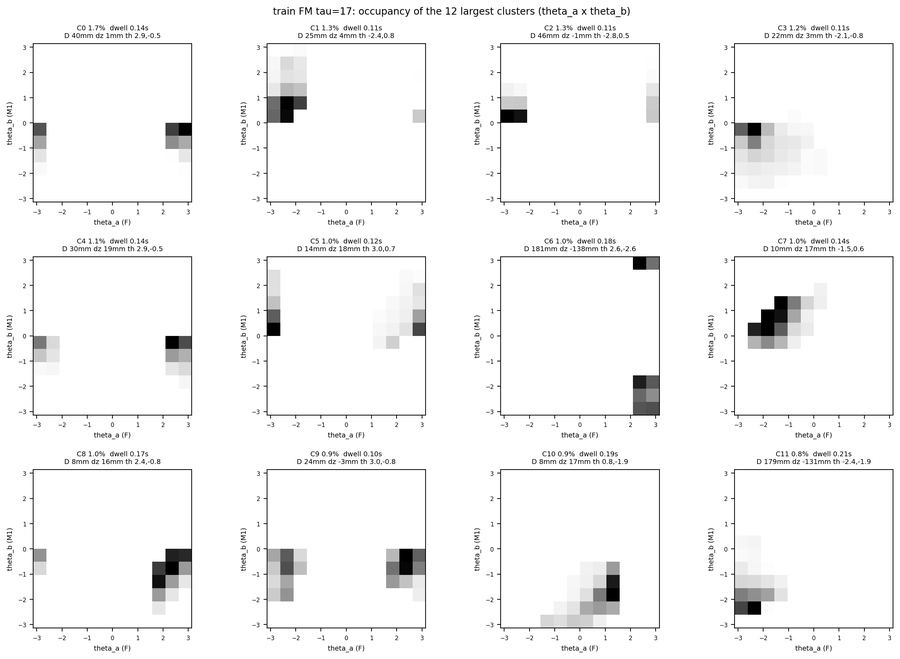

  fig figures/03_cluster_dxy_dz__FM__tau17-dmax150-bd10-of-bz8-bth12__train.png



[train MM tau 7 (0.042 s)] clusters 1880; 1291 cover 95% of frames; largest 1.0%; within 0.788 (shuffle 0.616), no diagonal 0.449 (shuffle 0.001)
 cluster  n_states  frame_fraction  mean_dwell_s  within_fraction_nodiag  D_xy_median  dz_median  theta_a_mean  theta_b_mean  share_M1M2  share_K  partner  overlap  mutual
       0        12           0.010         0.238                   0.612      179.747    -63.619         2.617        -2.231       0.694    0.538        4    0.772    True
       1         9           0.008         0.231                   0.621      182.148   -129.443         2.384         2.931       0.851    0.465        2    1.000    True
       2         9           0.008         0.231                   0.621      182.148    129.443         2.931         2.384       0.149    0.465        1    1.000    True
       3        12           0.008         0.247                   0.691      179.303    129.722         2.379        -2.155       0.212    0.495       12    0.563  

  fig figures/03_cluster_matrix__MM__tau7-dmax150-bd10-of-bz8-bth12__train.png


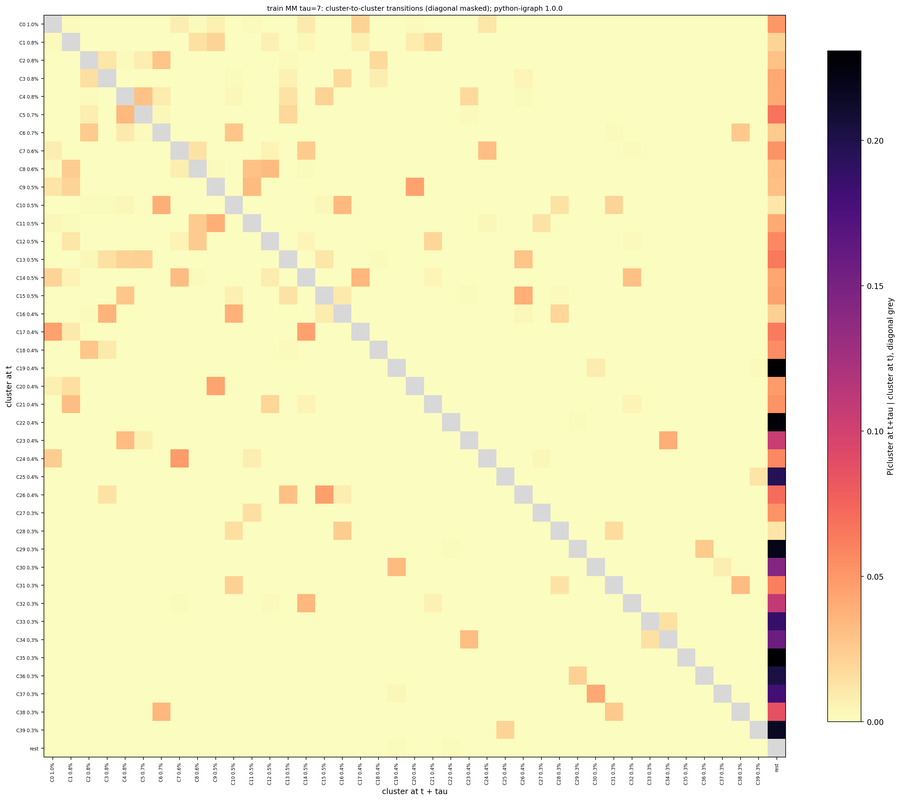

  fig figures/03_state_block__MM__tau7-dmax150-bd10-of-bz8-bth12__train.png


  fig figures/03_cluster_theta__MM__tau7-dmax150-bd10-of-bz8-bth12__train.png


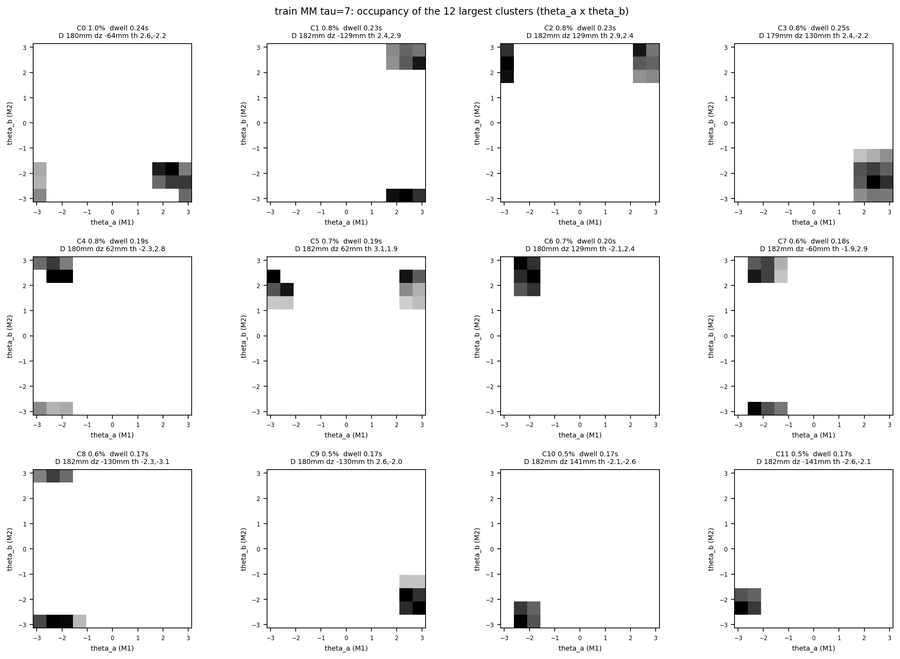

  fig figures/03_cluster_dxy_dz__MM__tau7-dmax150-bd10-of-bz8-bth12__train.png



[train MM tau 17 (0.102 s)] clusters 967; 610 cover 95% of frames; largest 1.4%; within 0.679 (shuffle 0.401), no diagonal 0.466 (shuffle 0.002)
 cluster  n_states  frame_fraction  mean_dwell_s  within_fraction_nodiag  D_xy_median  dz_median  theta_a_mean  theta_b_mean  share_M1M2  share_K  partner  overlap  mutual
       0        23           0.014         0.256                   0.623      175.130   -136.698         2.984        -2.102       0.875    0.514        2    0.863    True
       1        18           0.014         0.284                   0.615      180.800    -62.890         2.559        -2.509       0.694    0.546        4    0.830    True
       2        29           0.014         0.237                   0.597      170.291    137.894        -2.144        -3.055       0.157    0.524        0    0.905    True
       3        25           0.012         0.318                   0.703      178.580   -130.553        -2.703         1.702       0.801    0.526       10    0.710   

  fig figures/03_cluster_matrix__MM__tau17-dmax150-bd10-of-bz8-bth12__train.png


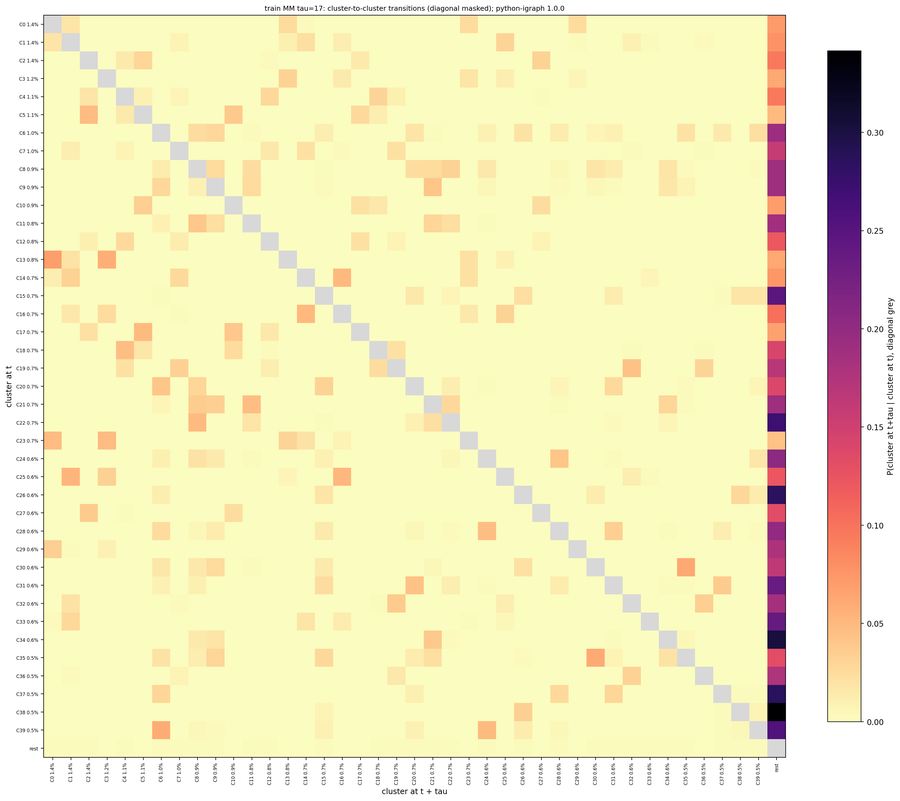

  fig figures/03_state_block__MM__tau17-dmax150-bd10-of-bz8-bth12__train.png


  fig figures/03_cluster_theta__MM__tau17-dmax150-bd10-of-bz8-bth12__train.png


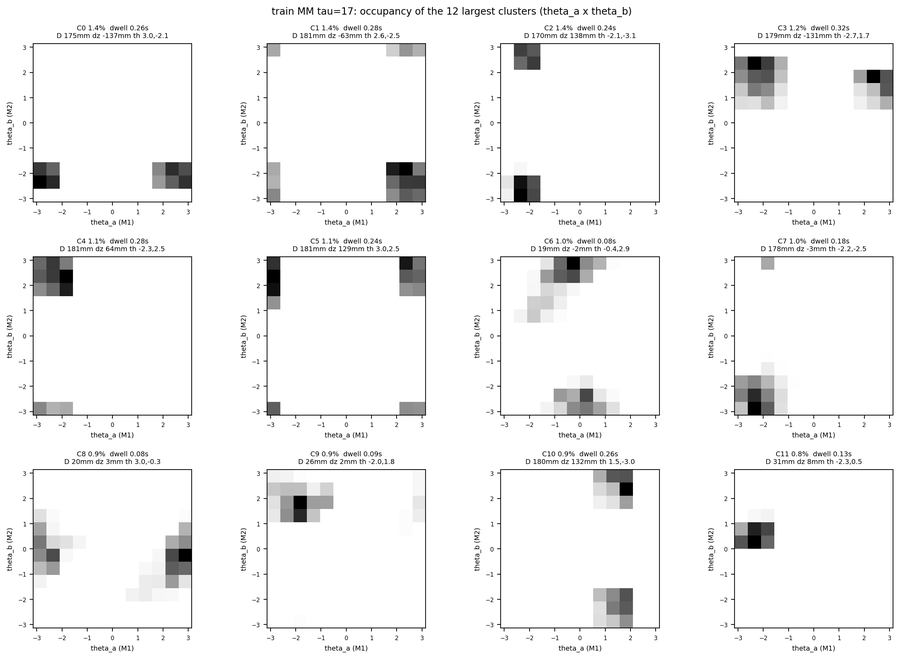

  fig figures/03_cluster_dxy_dz__MM__tau17-dmax150-bd10-of-bz8-bth12__train.png
  csv data/03_within_summary__all__dmax150-bd10-of-bz8-bth12__train.csv  rows 4
unit  tau  tau_s  n_clusters  n_clusters_95pct  largest_cluster_frame_fraction  median_states_per_cluster  occupied_states  valid_pairs  within  within_nodiag  shuffle_within_mean  shuffle_within_nodiag_mean  codelength  mirror_mutual_pairs  mirror_self_symmetric  mirror_frame_fraction_mutual
  FM    7  0.042        2282              1597                           0.009                        5.0            12286      2586504   0.807          0.445                0.653                       0.001       6.658                  NaN                    NaN                           NaN
  FM   17  0.102        1225               807                           0.017                        8.0            12276      2555257   0.705          0.468                0.446                       0.001       8.244                  NaN            

In [7]:
# Step 3 (continued): statistics and figures for the training-set clustering.
CMAP_W = plt.get_cmap("viridis").copy()
CMAP_W.set_bad("white")
STATS = {}
SUMMARY = []
for unit in UNITS:
    mic = load_micro(unit, "train")
    st = mic["state"].astype(np.int64)
    seg, vals, cop, exp = mic["seg"], mic["vals"].astype(np.float64), mic["copy"], mic["exp"]
    exp_names = [str(x) for x in mic["exp_names"]]
    copy_names = [str(x) for x in mic["copy_names"]]
    is_k = np.array([exp_group(e).startswith("K") for e in exp_names])[exp]
    for tau in TAUS:
        ctx = CTX[("train", unit, tau)]
        lab, cover, counts, keep = LABELS[("train", unit, tau)], ctx["cover"], ctx["counts"], ctx["keep"]
        fps = float(load_exp(TRAIN_EXPERIMENTS[0])["fps"])
        tp = tau_p(tau)
        k = len(cover)
        cl = np.where(st >= 0, lab[np.clip(st, 0, None)], -1)
        n_valid = int((st >= 0).sum())
        cum = np.cumsum(cover) / n_valid
        n_sel = int(np.searchsorted(cum, COVERAGE) + 1)
        n_st = np.bincount(lab[lab >= 0], minlength=k)
        # per-cluster statistics from frame-level values
        m = cl >= 0
        df = pd.DataFrame({"cluster": cl[m], "D_xy": vals[m, 0], "dz": vals[m, 1],
                           "sa": np.sin(vals[m, 2]), "ca": np.cos(vals[m, 2]),
                           "sb": np.sin(vals[m, 3]), "cb": np.cos(vals[m, 3]),
                           "copy0": cop[m] == 0, "K": is_k[m]})
        agg = df.groupby("cluster").agg(D_xy_median=("D_xy", "median"),
                                        D_xy_p10=("D_xy", lambda x: np.percentile(x, 10)),
                                        D_xy_p90=("D_xy", lambda x: np.percentile(x, 90)),
                                        dz_median=("dz", "median"), sa=("sa", "sum"), ca=("ca", "sum"),
                                        sb=("sb", "sum"), cb=("cb", "sum"),
                                        share_copy0=("copy0", "mean"), share_K=("K", "mean")).reindex(np.arange(k))
        w_d = S.per_cluster_within(counts, lab)
        w_n = S.per_cluster_within(counts, lab, drop_diagonal=True)
        dw = S.dwell_runs(cl, seg).groupby("cluster")["length"].agg(["mean", "count"]).reindex(np.arange(k))
        stats = pd.DataFrame({
            "cluster": np.arange(k), "n_states": n_st, "n_frames": cover.astype(int),
            "frame_fraction": cover / n_valid, "selected": np.arange(k) < n_sel,
            "within_fraction": w_d["within_fraction"].to_numpy(),
            "within_fraction_nodiag": w_n["within_fraction"].to_numpy(),
            "mean_dwell_s": dw["mean"].to_numpy() / fps, "n_dwell_runs": dw["count"].fillna(0).astype(int).to_numpy(),
            "D_xy_median": agg["D_xy_median"].to_numpy(), "D_xy_p10": agg["D_xy_p10"].to_numpy(),
            "D_xy_p90": agg["D_xy_p90"].to_numpy(), "dz_median": agg["dz_median"].to_numpy(),
            "theta_a_mean": np.arctan2(agg["sa"], agg["ca"]).to_numpy(),
            "theta_b_mean": np.arctan2(agg["sb"], agg["cb"]).to_numpy(),
            f"share_{copy_names[0]}": agg["share_copy0"].to_numpy(), "share_K": agg["share_K"].to_numpy()})
        if unit == "MM":
            mir = P4.mirror_partners(lab, SWAP, ctx["state_frames"])
            stats = stats.merge(mir, on="cluster", how="left")
        STATS[(unit, tau)] = stats
        L.save_csv(stats, "03", "cluster_stats", unit, tp, "train", verbose=False)
        # within-cluster share vs shuffled labels
        rng = np.random.default_rng(INFOMAP_SEED)
        sh, sh_nd = [], []
        for _ in range(N_SHUFFLE):
            perm = lab.copy()
            perm[keep] = rng.permutation(lab[keep])
            sh.append(S.within_fraction(counts, perm))
            sh_nd.append(S.within_fraction(counts, perm, drop_diagonal=True))
        row = {"unit": unit, "tau": tau, "tau_s": tau / fps, "n_clusters": k, "n_clusters_95pct": n_sel,
               "largest_cluster_frame_fraction": cover[0] / n_valid, "median_states_per_cluster": float(np.median(n_st)),
               "occupied_states": len(keep), "valid_pairs": ctx["n_pairs"],
               "within": S.within_fraction(counts, lab), "within_nodiag": S.within_fraction(counts, lab, drop_diagonal=True),
               "shuffle_within_mean": np.mean(sh), "shuffle_within_nodiag_mean": np.mean(sh_nd),
               "codelength": ctx["codelength"]}
        if unit == "MM":
            row["mirror_mutual_pairs"] = int((stats["mutual"] & ~stats["self_symmetric"]).sum() // 2)
            row["mirror_self_symmetric"] = int(stats["self_symmetric"].sum())
            row["mirror_frame_fraction_mutual"] = float(stats.loc[stats["mutual"], "frame_fraction"].sum())
        SUMMARY.append(row)
        print(f"\n[train {unit} tau {tau} ({tau / fps:.3f} s)] clusters {k}; {n_sel} cover {100 * COVERAGE:.0f}% of frames; "
              f"largest {100 * cover[0] / n_valid:.1f}%; within {row['within']:.3f} (shuffle {row['shuffle_within_mean']:.3f}), "
              f"no diagonal {row['within_nodiag']:.3f} (shuffle {row['shuffle_within_nodiag_mean']:.3f})")
        cols = ["cluster", "n_states", "frame_fraction", "mean_dwell_s", "within_fraction_nodiag", "D_xy_median",
                "dz_median", "theta_a_mean", "theta_b_mean", f"share_{copy_names[0]}", "share_K"]
        if unit == "MM":
            cols += ["partner", "overlap", "mutual"]
        print(stats.head(TOP_SHOW)[cols].round(3).to_string(index=False))

        # (a) cluster x cluster matrix
        n_show = min(n_sel, MAX_MATRIX, k)
        disp = np.where(lab >= 0, np.minimum(lab, n_show), -1)
        coo = counts.tocoo()
        okc = (disp[coo.row] >= 0) & (disp[coo.col] >= 0)
        nn = n_show + int(k > n_show)
        C = np.zeros((nn, nn))
        np.add.at(C, (disp[coo.row[okc]], disp[coo.col[okc]]), coo.data[okc])
        Pc = C / np.maximum(C.sum(axis=1, keepdims=True), 1)
        labels = [f"C{c} {100 * cover[c] / n_valid:.1f}%" for c in range(n_show)] + (["rest"] if k > n_show else [])
        show = np.ma.array(Pc, mask=np.eye(nn, dtype=bool))
        fig, ax = plt.subplots(figsize=(min(20, 0.38 * nn + 4), min(18, 0.34 * nn + 3.5)))
        cm = plt.get_cmap("magma_r").copy()
        cm.set_bad("0.85")
        im = ax.imshow(show, cmap=cm, vmin=0, vmax=max(float(show.max()), 1e-6), interpolation="nearest")
        ax.set_xticks(np.arange(nn), labels, rotation=90, fontsize=6)
        ax.set_yticks(np.arange(nn), labels, fontsize=6)
        ax.set_xlabel("cluster at t + tau")
        ax.set_ylabel("cluster at t")
        fig.colorbar(im, ax=ax, fraction=0.04, label="P(cluster at t+tau | cluster at t), diagonal grey")
        ax.set_title(f"train {unit} tau={tau}: cluster-to-cluster transitions (diagonal masked); {BACKEND_TAG}", fontsize=9)
        save_fig(fig, "03", "cluster_matrix", unit, tp, "train", show=True)

        # (b) state-level block view (sparse scatter; states ordered by cluster)
        sel_states = np.flatnonzero((lab >= 0) & (lab < n_show))
        order = sel_states[np.lexsort((sel_states, lab[sel_states]))]
        pos = np.full(N_STATES, -1)
        pos[order] = np.arange(len(order))
        pr = S.row_normalize(counts).tocoo()
        okp = (pos[pr.row] >= 0) & (pos[pr.col] >= 0)
        fig, ax = plt.subplots(figsize=(10, 10))
        sc = ax.scatter(pos[pr.col[okp]], pos[pr.row[okp]], c=np.log10(pr.data[okp]), s=0.3, marker="s",
                        cmap="viridis", vmin=-3, vmax=0, linewidths=0)
        bounds = np.flatnonzero(np.diff(lab[order]) != 0) + 0.5
        for b in bounds:
            ax.axhline(b, color="0.7", lw=0.2)
            ax.axvline(b, color="0.7", lw=0.2)
        ax.set_xlim(-0.5, len(order) - 0.5)
        ax.set_ylim(len(order) - 0.5, -0.5)
        ax.set_xlabel("state at t + tau (ordered by cluster)")
        ax.set_ylabel("state at t")
        fig.colorbar(sc, ax=ax, fraction=0.04, label="log10 P(s_t+tau | s_t)")
        ax.set_title(f"train {unit} tau={tau}: {len(order)} states of the {n_show} largest clusters", fontsize=9)
        save_fig(fig, "03", "state_block", unit, tp, "train")

        # (c) cluster maps: theta_a x theta_b and D_xy x dz occupancy of the largest clusters
        dec = P4.decode(np.arange(N_STATES), WIDTHS)
        sf = ctx["state_frames"]
        ncol = 4
        nrow = int(np.ceil(min(TOP_SHOW, k) / ncol))
        for which in ("theta", "dxy_dz"):
            fig, axes = plt.subplots(nrow, ncol, figsize=(3.4 * ncol, 3.2 * nrow), squeeze=False)
            for c in range(nrow * ncol):
                ax = axes[c // ncol, c % ncol]
                if c >= min(TOP_SHOW, k):
                    ax.axis("off")
                    continue
                stc = np.flatnonzero(lab == c)
                if which == "theta":
                    H = np.zeros((WIDTHS[2], WIDTHS[3]))
                    np.add.at(H, (dec[stc, 2], dec[stc, 3]), sf[stc])
                    ax.imshow(H.T, origin="lower", extent=[-np.pi, np.pi, -np.pi, np.pi], cmap="Greys")
                    ax.set_xlabel(f"theta_a ({UNITS[unit][0][0]})", fontsize=7)
                    ax.set_ylabel(f"theta_b ({UNITS[unit][0][1]})", fontsize=7)
                else:
                    H = np.zeros((WIDTHS[0], WIDTHS[1]))
                    np.add.at(H, (dec[stc, 0], dec[stc, 1]), sf[stc])
                    ax.imshow(H.T, origin="lower", aspect="auto", cmap="Greys")
                    ax.set_xticks(np.arange(WIDTHS[0]), [f"{e:.0f}" for e in EDGES[0][:-1]], fontsize=5, rotation=90)
                    ax.set_yticks(np.arange(WIDTHS[1]), [f"{e:.0f}" for e in EDGES[1][:-1]], fontsize=5)
                    ax.set_xlabel("D_xy bin lower edge (mm)", fontsize=7)
                    ax.set_ylabel("dz bin lower edge (mm)", fontsize=7)
                r = stats.iloc[c]
                ax.set_title(f"C{c} {100 * r.frame_fraction:.1f}%  dwell {r.mean_dwell_s:.2f}s\n"
                             f"D {r.D_xy_median:.0f}mm dz {r.dz_median:.0f}mm "
                             f"th {r.theta_a_mean:.1f},{r.theta_b_mean:.1f}", fontsize=7)
                ax.tick_params(labelsize=6)
            fig.suptitle(f"train {unit} tau={tau}: occupancy of the {min(TOP_SHOW, k)} largest clusters "
                         f"({'theta_a x theta_b' if which == 'theta' else 'D_xy x dz'})", fontsize=10)
            fig.tight_layout()
            save_fig(fig, "03", f"cluster_{which}", unit, tp, "train", show=(which == "theta"))
SUMMARY_T = pd.DataFrame(SUMMARY)
L.save_csv(SUMMARY_T, "03", "within_summary", "all", STATE_P, "train")
print(SUMMARY_T.round(3).to_string(index=False))
L.log("03", "done")

## Step 4 — 测试集泛化，以及每个实验、每个配对的簇使用频率

**做什么**（每个单元、每个 τ）：
1. 测试集的每帧状态用**训练集**的状态→簇表查簇。打印测试帧中有簇的比例（状态在训练图里出现过）。
2. 簇占用分布：训练 vs 测试的 Jensen-Shannon 距离（整体，以及按副本 FM1/FM2/M1M2/M2M1）；散点图 `04_occupancy_train_test`。
3. 测试集独立 Infomap（Step 3 已跑）与"训练簇投影"在测试帧上的一致性：ARI、NMI。
4. 6 个实验 × 每个副本落在最大 `TOP_SHOW` 个簇的比例：`data/04_usage`、热图 `04_usage`。这是之后比较 F-M1 vs F-M2、K vs P、第 1/2/3 次实验的基础。

**输出**：`data/04_generalization__all__…__test.csv`、`data/04_usage__<unit>__<tau…>__all.csv`、图 `04_occupancy_train_test`、`04_usage`。

  fig figures/04_occupancy_train_test__FM__tau7-dmax150-bd10-of-bz8-bth12__test.png


  fig figures/04_usage__FM__tau7-dmax150-bd10-of-bz8-bth12__all.png


  fig figures/04_occupancy_train_test__FM__tau17-dmax150-bd10-of-bz8-bth12__test.png


  fig figures/04_usage__FM__tau17-dmax150-bd10-of-bz8-bth12__all.png


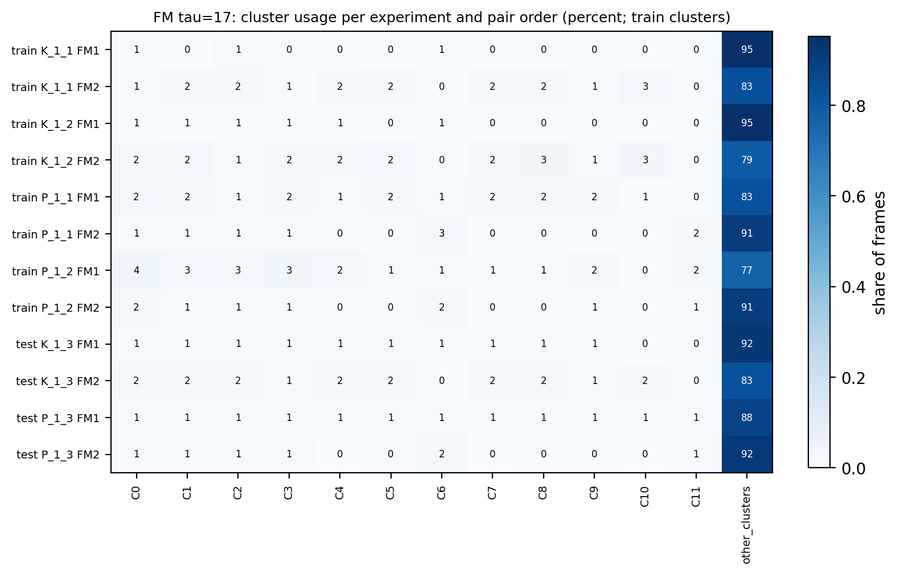

  fig figures/04_occupancy_train_test__MM__tau7-dmax150-bd10-of-bz8-bth12__test.png


  fig figures/04_usage__MM__tau7-dmax150-bd10-of-bz8-bth12__all.png


  fig figures/04_occupancy_train_test__MM__tau17-dmax150-bd10-of-bz8-bth12__test.png


  fig figures/04_usage__MM__tau17-dmax150-bd10-of-bz8-bth12__all.png


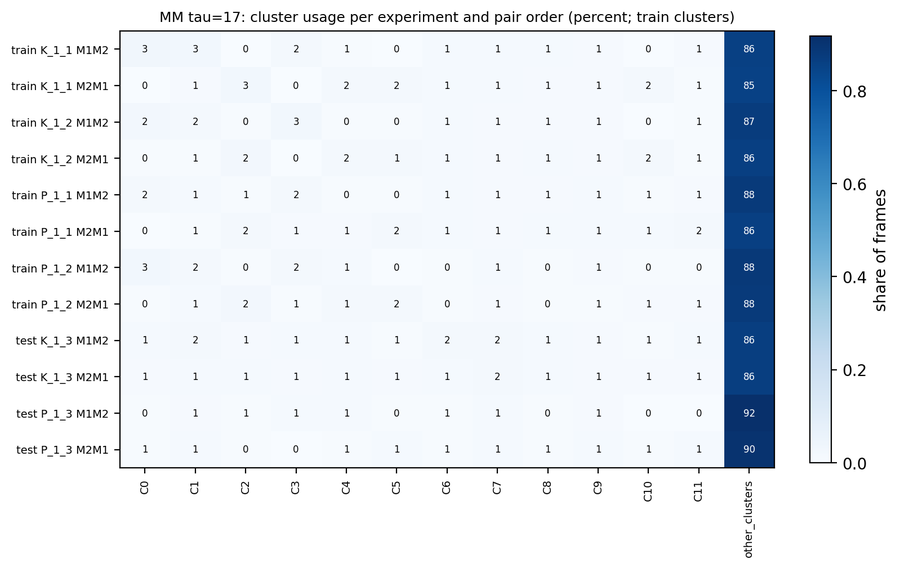

  csv data/04_generalization__all__dmax150-bd10-of-bz8-bth12__test.csv  rows 4
                                             0        1        2        3
unit                                        FM       FM       MM       MM
tau                                          7       17        7       17
test_frames_with_state                 1287583  1287583  1297260  1297260
test_frames_in_train_clusters_percent   99.447   99.432   99.693   99.693
js_train_test                            0.229    0.192    0.198    0.163
test_own_clusters                         2152     1305     1878     1108
train_clusters                            2282     1225     1880      967
ari_train_map_vs_test_infomap            0.487    0.359    0.441      0.3
nmi_train_map_vs_test_infomap            0.864    0.796    0.843    0.767
js_FM1                                   0.298    0.253      NaN      NaN
js_FM2                                   0.303    0.251      NaN      NaN
js_M1M2                          

In [8]:
# Step 4: test-set generalisation and per-experiment cluster usage.
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
L.clear_log("04")
GEN = []
for unit in UNITS:
    for tau in TAUS:
        tp = tau_p(tau)
        lab_tr = LABELS[("train", unit, tau)]
        lab_te = LABELS[("test", unit, tau)]
        k = int(lab_tr.max()) + 1
        tr = load_micro(unit, "train")
        te = load_micro(unit, "test")
        st_tr, st_te = tr["state"].astype(np.int64), te["state"].astype(np.int64)
        cl_tr = np.where(st_tr >= 0, lab_tr[np.clip(st_tr, 0, None)], -1)
        cl_te = np.where(st_te >= 0, lab_tr[np.clip(st_te, 0, None)], -1)
        own_te = np.where(st_te >= 0, lab_te[np.clip(st_te, 0, None)], -1)
        has = st_te >= 0
        occ_tr = np.bincount(cl_tr[cl_tr >= 0], minlength=k)
        occ_te = np.bincount(cl_te[cl_te >= 0], minlength=k)
        both = (cl_te >= 0) & (own_te >= 0)
        row = {"unit": unit, "tau": tau, "test_frames_with_state": int(has.sum()),
               "test_frames_in_train_clusters_percent": 100.0 * (cl_te >= 0).sum() / max(has.sum(), 1),
               "js_train_test": S.js_distance(occ_tr, occ_te),
               "test_own_clusters": int(lab_te.max()) + 1, "train_clusters": k,
               "ari_train_map_vs_test_infomap": adjusted_rand_score(cl_te[both], own_te[both]),
               "nmi_train_map_vs_test_infomap": normalized_mutual_info_score(cl_te[both], own_te[both])}
        for ci, cp in enumerate(COPIES[unit]):
            a = np.bincount(cl_tr[(cl_tr >= 0) & (tr["copy"] == ci)], minlength=k)
            b = np.bincount(cl_te[(cl_te >= 0) & (te["copy"] == ci)], minlength=k)
            row[f"js_{cp}"] = S.js_distance(a, b)
        GEN.append(row)
        # occupancy scatter
        fig, ax = plt.subplots(figsize=(5.5, 5.2))
        p_tr, p_te = occ_tr / occ_tr.sum(), occ_te / max(occ_te.sum(), 1)
        ax.loglog(p_tr + 1e-7, p_te + 1e-7, ".", ms=3, alpha=0.6)
        for c in range(min(TOP_SHOW, k)):
            ax.annotate(f"C{c}", (p_tr[c], p_te[c] + 1e-7), fontsize=6)
        lim = [1e-7, 1]
        ax.plot(lim, lim, "k:", lw=0.8)
        ax.set_xlabel("frame share in train")
        ax.set_ylabel("frame share in test (train clusters)")
        ax.set_title(f"{unit} tau={tau}: cluster occupancy, JS={row['js_train_test']:.3f}, "
                     f"ARI vs own test Infomap={row['ari_train_map_vs_test_infomap']:.2f}", fontsize=8)
        save_fig(fig, "04", "occupancy_train_test", unit, tp, "test")
        # usage per experiment x copy
        rows = []
        for set_name, mic, clv in (("train", tr, cl_tr), ("test", te, cl_te)):
            for ei, e in enumerate([str(x) for x in mic["exp_names"]]):
                for ci, cp in enumerate([str(x) for x in mic["copy_names"]]):
                    m = (mic["exp"] == ei) & (mic["copy"] == ci) & (clv >= 0)
                    cnt = np.bincount(clv[m], minlength=k)
                    r = {"set": set_name, "experiment": e, "copy": cp, "frames": int(m.sum())}
                    for c in range(min(TOP_SHOW, k)):
                        r[f"C{c}"] = cnt[c] / max(m.sum(), 1)
                    r["other_clusters"] = cnt[min(TOP_SHOW, k):].sum() / max(m.sum(), 1)
                    rows.append(r)
        U = pd.DataFrame(rows)
        L.save_csv(U, "04", "usage", unit, tp, "all", verbose=False)
        mat = U[[c for c in U.columns if c.startswith("C") or c == "other_clusters"]].to_numpy(float)
        fig, ax = plt.subplots(figsize=(1.0 + 0.55 * mat.shape[1], 1.2 + 0.32 * len(U)))
        im = ax.imshow(mat, cmap="Blues", aspect="auto", vmin=0)
        for (i, j), v in np.ndenumerate(mat):
            ax.text(j, i, f"{100 * v:.0f}", ha="center", va="center", fontsize=6,
                    color="white" if v > 0.6 * mat.max() else "black")
        ax.set_yticks(np.arange(len(U)), [f"{s} {exp_short(e)} {c}" for s, e, c in zip(U["set"], U["experiment"], U["copy"])],
                      fontsize=7)
        ax.set_xticks(np.arange(mat.shape[1]), [c for c in U.columns if c.startswith("C") or c == "other_clusters"],
                      rotation=90, fontsize=7)
        fig.colorbar(im, ax=ax, fraction=0.03, label="share of frames")
        ax.set_title(f"{unit} tau={tau}: cluster usage per experiment and pair order (percent; train clusters)", fontsize=9)
        save_fig(fig, "04", "usage", unit, tp, "all", show=(tau == TAUS[-1]))
GEN_T = pd.DataFrame(GEN)
L.save_csv(GEN_T, "04", "generalization", "all", STATE_P, "test")
print(GEN_T.round(3).T.to_string())
L.log("04", "done")

## Step 5 — 用 BORIS 标注验证簇（本 notebook 唯一读取标注的地方）

**标注到配对的对应**：一条 bout 属于配对 {a, b}，当 `who` 是 `X->Y` 或 `X<->Y` 且 {X, Y} = {a, b}。FM 的标签就是类别名（所有 F-M 标注都是 M→F）；MM 的标签带方向：`a->b`、`b->a`、`a<->b`（a、b 是本副本的第一、第二条鱼，所以 M1M2 和 M2M1 两个副本里同一条 bout 方向相反，这正好与对称化一致）。

**做什么**（每个单元、每个 τ）：
1. 标注统计 `data/05_label_counts`：每个实验 × 配对 × 类别的帧数（K 组和 P 组词汇不同，P 组有大量 follow，K 组没有；请对照看）。
2. 富集：P(类别 | 簇) / P(类别)，最大 `TOP_SHOW` 个簇，训练集和测试集（测试帧用训练簇）各一张 `05_enrichment`。
3. 簇→类别映射：只用训练集带标注的帧（不含 none/unmapped），每簇取多数类别，纯度 < `MIN_PURITY` 记为 unassigned；在测试集带标注的帧上评估：混淆矩阵 `05_confusion`、每类精确率/召回率、整体准确率与多数类基线 `data/05_eval`。
4. 示例 ethogram `05_ethogram`：`ETHOGRAM_EXPERIMENT` 中一段 `ETHOGRAM_WINDOW_S` 秒（默认自动选 FM1+FM2 上 `ETHOGRAM_CLASS` 帧最多的一段），上为簇序列（颜色 = 簇号 mod 20，只用来看切换；无状态为白色），下为 BORIS 类别。

  csv data/05_label_counts__all__base__all.csv  rows 80
experiment                       K_1_1     K_1_2     K_1_3     P_1_1     P_1_3     P_1_2
pair label                                                                              
FM1  aggression                    0.0       0.0       0.0      26.0      34.0     165.0
     approach_follow            1280.0       0.0       0.0   38894.0  237075.0   75504.0
     courtship                   303.0    2230.0     827.0    3001.0    4215.0    2109.0
     none                     347017.0  341647.0  347475.0  297616.0  107078.0  267409.0
     unmapped                      0.0       0.0       0.0       0.0       0.0    1718.0
     wrap                          0.0    4723.0     298.0    9063.0     198.0    1695.0
FM2  aggression                    0.0     162.0      43.0      15.0      55.0       9.0
     approach_follow            1105.0       0.0       0.0    9444.0   24392.0    7887.0
     courtship                 12315.0   11896.0   130

  fig figures/05_enrichment__FM__tau7-dmax150-bd10-of-bz8-bth12__train-test.png


  fig figures/05_confusion__FM__tau7-dmax150-bd10-of-bz8-bth12__test.png


  fig figures/05_enrichment__FM__tau17-dmax150-bd10-of-bz8-bth12__train-test.png


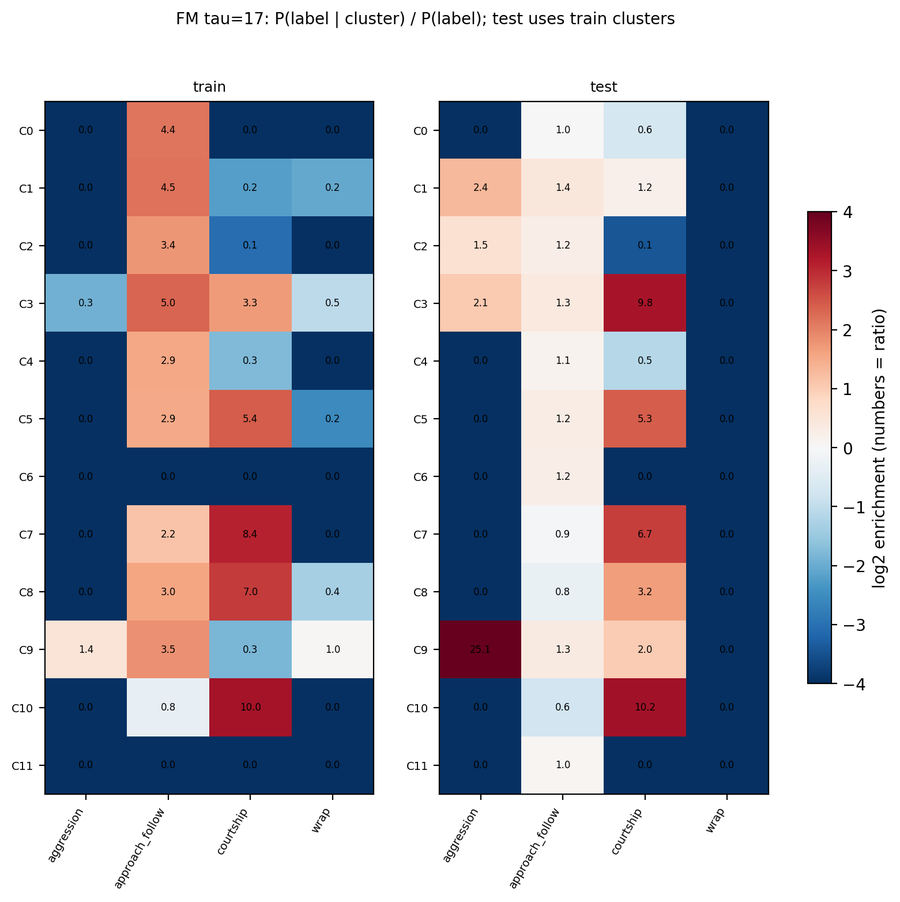

  fig figures/05_confusion__FM__tau17-dmax150-bd10-of-bz8-bth12__test.png


  fig figures/05_enrichment__MM__tau7-dmax150-bd10-of-bz8-bth12__train-test.png


  fig figures/05_confusion__MM__tau7-dmax150-bd10-of-bz8-bth12__test.png


  fig figures/05_enrichment__MM__tau17-dmax150-bd10-of-bz8-bth12__train-test.png


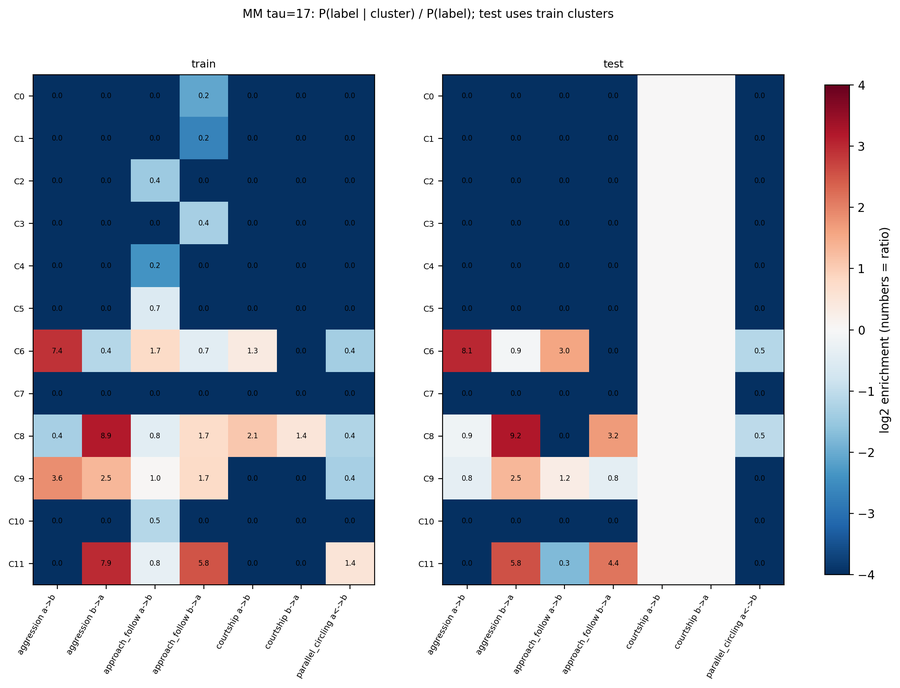

  fig figures/05_confusion__MM__tau17-dmax150-bd10-of-bz8-bth12__test.png
  csv data/05_eval__all__dmax150-bd10-of-bz8-bth12__test.csv  rows 4
                                                              0                1                     2                     3
unit                                                         FM               FM                    MM                    MM
tau                                                           7               17                     7                    17
test_labelled_frames                                     289608           289608                 93156                 93156
accuracy                                                  0.388            0.449                  0.73                 0.703
majority_baseline                                         0.903            0.903                 0.445                 0.445
majority_class                                  approach_follow  approach_follow  approach_follow b->a  app

In [9]:
# Step 5: BORIS labels per pair order, enrichment, train->test label mapping, ethogram.
L.clear_log("05")
CLASSES = list(LABEL_CLASSES)
FRAME_LABELS = {}   # (experiment, copy) -> label per frame
lc_rows = []
for e in ALL_EXPERIMENTS:
    bouts = M.bouts_of(e)
    frames = load_exp(e)["frames"]
    for cp, (a, b) in COPY_PAIR.items():
        lab = P4.pair_frame_labels(bouts, a, b, frames, LABEL_CLASSES, directed=(UNIT_OF[cp] == "MM"))
        FRAME_LABELS[(e, cp)] = lab
        if cp in PAIR_COPIES:
            vc = pd.Series(lab).value_counts()
            for name, n in vc.items():
                lc_rows.append({"experiment": e, "set": "train" if e in TRAIN_EXPERIMENTS else "test",
                                "pair": cp, "label": name, "frames": int(n)})
LC = pd.DataFrame(lc_rows)
L.save_csv(LC, "05", "label_counts", "all", "base", "all")
print(LC.pivot_table(index=["pair", "label"], columns="experiment", values="frames", fill_value=0)
      .rename(columns=exp_short).to_string())


def labels_for(mic):
    out = np.empty(len(mic["state"]), dtype=object)
    for ei, e in enumerate([str(x) for x in mic["exp_names"]]):
        for ci, cp in enumerate([str(x) for x in mic["copy_names"]]):
            m = (mic["exp"] == ei) & (mic["copy"] == ci)
            out[m] = FRAME_LABELS[(e, cp)]
    return out


EVAL = []
for unit in UNITS:
    tr, te = load_micro(unit, "train"), load_micro(unit, "test")
    y_tr, y_te = labels_for(tr), labels_for(te)
    for tau in TAUS:
        tp = tau_p(tau)
        lab_tr = LABELS[("train", unit, tau)]
        k = int(lab_tr.max()) + 1
        st_tr, st_te = tr["state"].astype(np.int64), te["state"].astype(np.int64)
        cl_tr = np.where(st_tr >= 0, lab_tr[np.clip(st_tr, 0, None)], -1)
        cl_te = np.where(st_te >= 0, lab_tr[np.clip(st_te, 0, None)], -1)
        present = sorted({x for x in np.unique(np.concatenate([y_tr, y_te])) if x not in ("none", "unmapped")})
        # enrichment of the largest clusters
        ids = list(range(min(TOP_SHOW, k)))
        fig, axes = plt.subplots(1, 2, figsize=(4 + 1.2 * len(present), 0.4 * len(ids) + 3), squeeze=False)
        for ax, (nm, clv, yv) in zip(axes[0], (("train", cl_tr, y_tr), ("test", cl_te, y_te))):
            E = P4.enrichment(clv, yv, ids, present)
            L.save_csv(E.reset_index().rename(columns={"index": "cluster"}), "05", "enrichment", unit, tp, nm, verbose=False)
            Z = np.log2(E.to_numpy(float).clip(1 / 64, 64))
            im = ax.imshow(np.where(np.isfinite(Z), Z, 0), cmap="RdBu_r", vmin=-4, vmax=4, aspect="auto")
            for (i, j), v in np.ndenumerate(E.to_numpy(float)):
                if np.isfinite(v):
                    ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=6)
            ax.set_xticks(np.arange(len(present)), present, rotation=60, ha="right", fontsize=7)
            ax.set_yticks(np.arange(len(ids)), [f"C{c}" for c in ids], fontsize=7)
            ax.set_title(f"{nm}", fontsize=9)
        fig.colorbar(im, ax=axes[0].tolist(), fraction=0.03, label="log2 enrichment (numbers = ratio)")
        fig.suptitle(f"{unit} tau={tau}: P(label | cluster) / P(label); test uses train clusters", fontsize=10)
        save_fig(fig, "05", "enrichment", unit, tp, "train-test", show=(tau == TAUS[-1]))
        # train -> test mapping
        mp = P4.fit_label_map(cl_tr, y_tr, MIN_PURITY)
        L.save_csv(mp, "05", "label_map", unit, tp, "train", verbose=False)
        lut = dict(zip(mp["cluster"], mp["mapped_label"]))
        lab_te_m = ~np.isin(y_te, ["none", "unmapped"])
        pred = np.array([lut.get(int(c), "unassigned") if c >= 0 else "no_state" for c in cl_te[lab_te_m]], dtype=object)
        true = y_te[lab_te_m]
        cols = present + ["unassigned", "no_state"]
        conf = pd.crosstab(pd.Categorical(true, categories=present), pd.Categorical(pred, categories=cols), dropna=False)
        L.save_csv(conf.reset_index().rename(columns={"row_0": "true"}), "05", "confusion", unit, tp, "test", verbose=False)
        acc = float(np.mean(pred == true)) if len(true) else np.nan
        base_cls = pd.Series(true).value_counts().index[0] if len(true) else None
        base = float(np.mean(true == base_cls)) if len(true) else np.nan
        pred_none = np.array([lut.get(int(c), "unassigned") for c in cl_te[(y_te == "none") & (cl_te >= 0)]], dtype=object)
        row = {"unit": unit, "tau": tau, "test_labelled_frames": int(lab_te_m.sum()), "accuracy": acc,
               "majority_baseline": base, "majority_class": base_cls,
               "mapped_clusters": int((mp["mapped_label"] != "unassigned").sum()),
               "unlabelled_frames_predicted_as_a_class_percent": 100.0 * np.mean(pred_none != "unassigned") if len(pred_none) else np.nan}
        for c in present:
            tp_ = int(((pred == c) & (true == c)).sum())
            row[f"recall_{c}"] = tp_ / max(int((true == c).sum()), 1)
            row[f"precision_{c}"] = tp_ / max(int((pred == c).sum()), 1)
        EVAL.append(row)
        cn = conf.to_numpy(float)
        cr = cn / np.maximum(cn.sum(axis=1, keepdims=True), 1)
        fig, ax = plt.subplots(figsize=(1.5 + 0.8 * len(cols), 1.5 + 0.5 * len(present)))
        im = ax.imshow(cr, cmap="Blues", vmin=0, vmax=1, aspect="auto")
        for (i, j), v in np.ndenumerate(cn):
            ax.text(j, i, f"{int(v)}\n{100 * cr[i, j]:.0f}%", ha="center", va="center", fontsize=6)
        ax.set_xticks(np.arange(len(cols)), cols, rotation=60, ha="right", fontsize=7)
        ax.set_yticks(np.arange(len(present)), present, fontsize=7)
        ax.set_xlabel("predicted (train cluster -> majority label)")
        ax.set_ylabel("BORIS (test)")
        ax.set_title(f"{unit} tau={tau}: test accuracy {acc:.2f} (majority baseline {base:.2f})", fontsize=9)
        save_fig(fig, "05", "confusion", unit, tp, "test")
EVAL_T = pd.DataFrame(EVAL)
L.save_csv(EVAL_T, "05", "eval", "all", STATE_P, "test")
print(EVAL_T.round(3).T.to_string())

  fig figures/05_ethogram__all__tau7-dmax150-bd10-of-bz8-bth12__K_1_1.png


  fig figures/05_ethogram__all__tau17-dmax150-bd10-of-bz8-bth12__K_1_1.png


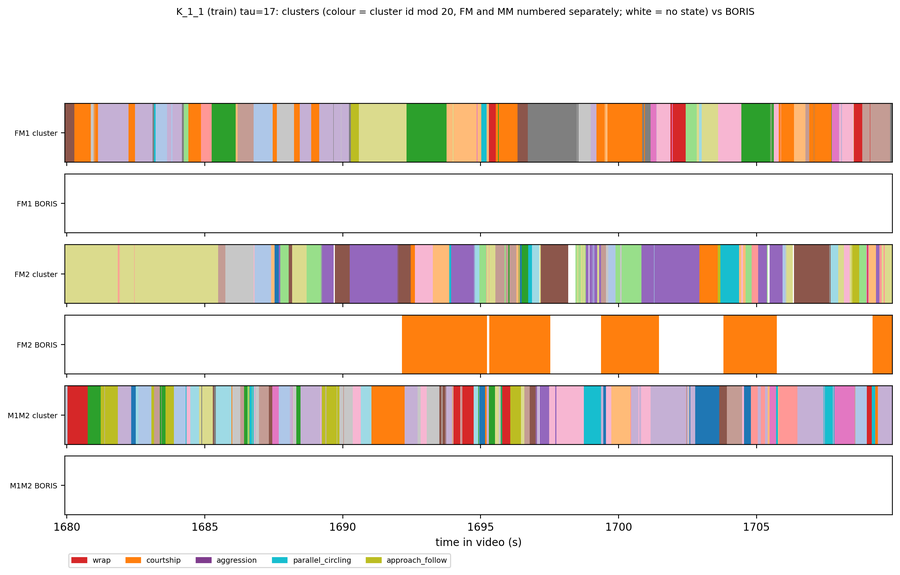

window 1679.9-1709.9 s


In [10]:
# Step 5 (continued): example ethogram (clusters vs BORIS) in one experiment.
e = ETHOGRAM_EXPERIMENT
set_e = "train" if e in TRAIN_EXPERIMENTS else "test"
z = load_exp(e)
fps = float(z["fps"])
win = int(ETHOGRAM_WINDOW_S * fps)
if ETHOGRAM_START_S is None:
    lab_fm = np.zeros(len(z["frames"]))
    for cp in COPIES["FM"]:
        lab_fm += FRAME_LABELS[(e, cp)] == ETHOGRAM_CLASS
    cs = np.concatenate([[0], np.cumsum(lab_fm)])
    start = int(np.argmax(cs[win:] - cs[:-win]))
else:
    start = int(ETHOGRAM_START_S * fps)
rows_spec = [("FM", "FM1"), ("FM", "FM2"), ("MM", "M1M2")]
for tau in TAUS:
    fig, axes = plt.subplots(2 * len(rows_spec), 1, figsize=(14, 1.0 * 2 * len(rows_spec) + 1), sharex=True)
    t = (np.arange(start, start + win)) / fps
    for r, (unit, cp) in enumerate(rows_spec):
        mic = load_micro(unit, set_e)
        ei = [str(x) for x in mic["exp_names"]].index(e)
        ci = [str(x) for x in mic["copy_names"]].index(cp)
        m = (mic["exp"] == ei) & (mic["copy"] == ci)
        st = mic["state"][m].astype(np.int64)[start:start + win]
        lab = LABELS[("train", unit, tau)]
        cl = np.where(st >= 0, lab[np.clip(st, 0, None)], -1)
        code_ = np.where(cl < 0, 0, cl % 20 + 1)
        cmap = ListedColormap(["white"] + list(plt.get_cmap("tab20").colors))
        ax = axes[2 * r]
        ax.imshow(code_[None, :], aspect="auto", cmap=cmap, vmin=-0.5, vmax=20.5,
                  extent=[t[0], t[-1], 0, 1], interpolation="nearest")
        ax.set_yticks([0.5], [f"{cp} cluster"], fontsize=7)
        bl = FRAME_LABELS[(e, cp)][start:start + win]
        base_cls = np.array([str(x).split(" ")[0] for x in bl])
        ax2 = axes[2 * r + 1]
        for c in CLASSES:
            mm = base_cls == c
            if mm.any():
                a0, a1 = S.bool_runs(mm)
                for s0, s1 in zip(a0, a1):
                    ax2.axvspan(t[s0], t[min(s1, len(t) - 1)], color=CLASS_COLOR.get(c, "k"), lw=0)
        ax2.set_yticks([0.5], [f"{cp} BORIS"], fontsize=7)
        ax2.set_ylim(0, 1)
    cls_h = [plt.Rectangle((0, 0), 1, 1, color=CLASS_COLOR[c]) for c in CLASSES]
    axes[-1].legend(cls_h, CLASSES, ncol=len(CLASSES), fontsize=7, loc="upper left", bbox_to_anchor=(0, -0.6))
    axes[-1].set_xlabel("time in video (s)")
    fig.suptitle(f"{exp_short(e)} ({set_e}) tau={tau}: clusters (colour = cluster id mod 20, FM and MM "
                 f"numbered separately; white = no state) vs BORIS", fontsize=9, y=1.06)
    save_fig(fig, "05", "ethogram", "all", tau_p(tau), exp_short(e), show=(tau == TAUS[-1]))
print(f"window {start / fps:.1f}-{(start + win) / fps:.1f} s")
L.log("05", "done")

## Step 6 — 总结表与输出清单

把 Step 3–5 的关键数字合并成 `summary.csv`（每个单元 × τ 一行），并列出输出目录里的文件。

In [11]:
# Step 6: summary table and file listing.
summ = SUMMARY_T.merge(GEN_T, on=["unit", "tau"]).merge(
    EVAL_T[["unit", "tau", "test_labelled_frames", "accuracy", "majority_baseline", "mapped_clusters"]], on=["unit", "tau"])
summ.to_csv(L.root / "summary.csv", index=False)
print(summ.round(3).T.to_string())
print("\noutput folder:", L.root)
for sub in ("figures", "data"):
    files = sorted(p.name for p in (L.root / sub).iterdir())
    print(f"\n{sub}/ ({len(files)} files)")
    for f in files:
        print("  ", f)

                                             0        1        2        3
unit                                        FM       FM       MM       MM
tau                                          7       17        7       17
tau_s                                    0.042    0.102    0.042    0.102
n_clusters                                2282     1225     1880      967
n_clusters_95pct                          1597      807     1291      610
largest_cluster_frame_fraction           0.009    0.017     0.01    0.014
median_states_per_cluster                  5.0      8.0      6.0     10.0
occupied_states                          12286    12276    12306    12306
valid_pairs                            2586504  2555257  2628250  2609858
within                                   0.807    0.705    0.788    0.679
within_nodiag                            0.445    0.468    0.449    0.466
shuffle_within_mean                      0.653    0.446    0.616    0.401
shuffle_within_nodiag_mean            